<img src="https://raw.githubusercontent.com/AI-MIND-Lab/MedPython/main/Images/ai-mind.png"
     alt="AI MIND Lab Logo"
     width="150"
     height="150">
<br>

**Repository Developed by Pegah Khosravi, Principal Investigator of the AI MIND Lab**

Welcome to this repository! This repository is a result of collaborative efforts from our dedicated team at the lab. We are committed to advancing the field of Medical AI and pushing the boundaries of medical data analysis. Your interest and contributions to our work are greatly appreciated. For more information about our lab and ongoing projects, please visit the [AI MIND Lab website](https://sites.google.com/view/aimindlab/home). Thank you for your interest and support!


#Week 3: Data Analysis with NumPy and Data Visualization with Matplotlib

**Objective: NumPy & Data Visualization Overview**
- NumPy arrays, indexing, operations, and basic statistics
- Working with numerical biological datasets
- Basic plots: line, scatter, histogram
- Customizing visuals (labels, titles, legends)
- Visualizing biological data
- Saving plots in Google Colab
- Short hands-on exercises






# Introduction to Core Concepts in Data Analysis and Statistics

Before using NumPy, we need to understand the quantities our code will calculate. This overview introduces the concepts through simple medical examples. No previous statistics course is assumed.

## 1. Mean: What Is the Average?

The **mean** is calculated by adding all values and dividing by the number of values.

For example, three fictional heart-rate measurements are:

```text
60, 70, 80 beats per minute
```

Their mean is:

```text
(60 + 70 + 80) / 3 = 70 beats per minute
```

The mean provides a summary, but it does not show how much the measurements differ.

**Think:** Could two patients have the same mean heart rate but different patterns of readings?

## 2. Median: What Is the Middle Value?

The **median** is the middle value after arranging the measurements from smallest to largest.

For example:

```text
60, 70, 80
```

The median is `70`.

If there is an even number of measurements, the median is the average of the two middle values.

The median is generally less sensitive to extreme values than the mean. For the fictional hospital stays below:

```text
2, 3, 3, 4, 18 days
```

The median is `3` days, while the mean is `6` days.

**Think:** Which summary better describes a typical stay in this small dataset? What information would we lose by reporting only one number?

## 3. Standard Deviation: How Spread Out Are the Values?

**Standard deviation**, often abbreviated **SD**, describes how spread out measurements are around their mean.

Compare these fictional heart-rate readings:

```text
Set A: 69, 70, 71 beats per minute
Set B: 50, 70, 90 beats per minute
```

Both sets have a mean of `70`, but Set B has a larger standard deviation because its values are more spread out.

Standard deviation has the same units as the measurements. For heart rate, its units are beats per minute.

**Important:** SD describes variability. It does not, by itself, explain its cause or establish a diagnosis.

## 4. Covariance: Do Two Measurements Vary Together?

**Covariance** describes how two numerical variables vary together across paired observations.

- **Positive covariance:** Values above the mean for one variable tend to occur with values above the mean for the other.
- **Negative covariance:** Values above the mean for one variable tend to occur with values below the mean for the other.
- **Covariance near zero:** There is little overall linear co-variation, although another kind of relationship may still exist.

For example, we might examine paired height and weight measurements from a group of fictional patients.

Covariance depends on the units used, so its magnitude can be difficult to interpret or compare across datasets.

## 5. Correlation: How Strong Is the Linear Relationship?

In this lesson, **correlation** means the **Pearson correlation coefficient**, written as `r`.

It measures the direction and strength of a linear relationship between two numerical variables:

- **`r = +1`:** A perfect increasing straight-line relationship.
- **`r = -1`:** A perfect decreasing straight-line relationship.
- **`r` near `0`:** Little or no linear relationship. A curved relationship may still exist.

Unlike covariance, correlation has no units.

For example, we might investigate whether two laboratory measurements tend to increase together across patients.

**Important:** Correlation does not establish causation. A relationship could reflect other variables, and unusual observations can strongly influence the result. Always examine a scatter plot alongside the coefficient.

## 6. Standardization: Expressing Values Relative to Their Mean

Measurements can have very different scales. For example, heart rate and laboratory concentrations use different units and numerical ranges.

**Z-score standardization** transforms each value using:

```text
z-score = (value − mean) / standard deviation
```

A standardized value tells us how far a measurement is from the dataset’s mean, expressed in standard deviations.

- A z-score of `0` means the value equals the mean.
- A z-score of `+1` means it is one SD above the mean.
- A z-score of `-1` means it is one SD below the mean.

We will use this transformation later in the notebook. Standardization changes the scale; it does not make measurements clinically equivalent, remove outliers, or turn a dataset into a normal distribution.

**Important:** If all values are identical, the SD is zero, so this formula would divide by zero. Our code must account for that case.

“Normalization” is a broader term used for several transformations. We will call this particular operation **z-score standardization**.

## 7. Filtering: Selecting Observations That Meet a Rule

**Filtering** selects values or records that satisfy a specified condition.

For example, a program could select fictional hospital records with a length of stay greater than seven days for a separate analysis.

The condition produces a `True` or `False` result for each record. NumPy can use these Boolean results to select the matching data.

Filtering answers a particular question; it does not automatically identify errors, establish statistical significance, or justify deleting excluded records.

**Think:** How might analyzing only longer hospital stays change the conclusions we draw about the hospital’s patients?

# Introduction to NumPy: Arrays and Numerical Operations

In Weeks 1 and 2, we used lists, loops, and functions to process data. **NumPy** adds tools for working with numerical collections, including tables of measurements.

Its main data structure is the **array**. Arrays support calculations on many values at once, often without writing an explicit Python loop.

For the numerical arrays in this lesson, values share a common data type. Unlike a general-purpose list, an array is designed for structured numerical operations.

## a) Importing NumPy

Run the next Code cell before using any NumPy examples.

```python
import numpy as np
```

- **`import`:** Makes a library available in the current session.
- **`numpy`:** The library we are importing.
- **`as np`:** Gives it the conventional short name `np`.

For example, `np.array(...)` calls NumPy’s array-creation function.

If the runtime restarts, run the import cell again.

In [11]:
import numpy as np

## b) Creating and Exploring Arrays

### One-Dimensional Arrays

A one-dimensional array stores a sequence of values, such as measurements from several samples.

```python
np.array([8.1, 7.4, 9.3])
```

The square brackets create a Python list. `np.array()` converts that list into a NumPy array.

### Two-Dimensional Arrays

A two-dimensional array stores a rectangular table.

In our example:

- Each **row** represents a gene.
- Each **column** represents a condition.
- Each value is a fictional expression measurement in arbitrary units.

### Useful Array Attributes

- **`.ndim`:** Number of dimensions.
- **`.shape`:** Size along each dimension. For a table, this is `(rows, columns)`.
- **`.dtype`:** Data type of the array’s elements.

These are attributes, so we access them without parentheses.

### Accessing Values

NumPy uses zero-based indexing:

- `array[0]` selects the first item of a one-dimensional array.
- `matrix[0, 1]` selects the first row and second column.
- `matrix[0, :]` selects every column in the first row.
- `matrix[:, 0]` selects every row in the first column.

The colon `:` means “select everything along this dimension.”

### Let's Explore NumPy Arrays with Python

Now that we understand the basic structure of NumPy arrays, let's create one-dimensional and two-dimensional arrays using fictional gene expression data.

In the following example, we will:
- Create a one-dimensional array and a two-dimensional matrix.
- Examine their dimensions, shapes, and data types.
- Practice indexing and slicing to access specific measurements.

**Before running the code:** Predict the shape of each array. Remember that Python indexing starts at `0`.

In [12]:
# A one-dimensional numerical array.
gene_expression_levels = np.array([8.1, 7.4, 9.3, 6.5, 8.8])

print("Expression values:", gene_expression_levels)
print("Dimensions:", gene_expression_levels.ndim)
print("Shape:", gene_expression_levels.shape)
print("Data type:", gene_expression_levels.dtype)

# Rows represent genes; columns represent conditions.
expression_matrix = np.array([
    [8.1, 7.4, 9.3],
    [6.5, 8.8, 7.2],
    [5.1, 6.4, 7.8]
])

print("\nExpression matrix:\n", expression_matrix)
print("Dimensions:", expression_matrix.ndim)
print("Shape:", expression_matrix.shape)

print("\nFirst expression value:", gene_expression_levels[0])
print("First gene, second condition:", expression_matrix[0, 1])
print("All conditions for the first gene:", expression_matrix[0, :])
print("All genes in the first condition:", expression_matrix[:, 0])

Expression values: [8.1 7.4 9.3 6.5 8.8]
Dimensions: 1
Shape: (5,)
Data type: float64

Expression matrix:
 [[8.1 7.4 9.3]
 [6.5 8.8 7.2]
 [5.1 6.4 7.8]]
Dimensions: 2
Shape: (3, 3)

First expression value: 8.1
First gene, second condition: 7.4
All conditions for the first gene: [8.1 7.4 9.3]
All genes in the first condition: [8.1 6.5 5.1]


## c) Basic Array Operations

NumPy can apply arithmetic to every element of an array.

This differs from list behavior:

- Multiplying a Python list by `2` repeats the list.
- Multiplying a numerical NumPy array by `2` doubles each value.

We can also add a constant, square each value, or multiply corresponding elements of two arrays.

In the example below, both arrays have the same shape, so their values are paired by position.

**Important:** For NumPy arrays, `*` means element-wise multiplication. It is different from matrix multiplication.

These calculations demonstrate programming operations. Adding a constant or multiplying measurements is not automatically an appropriate biological correction.

### Let's Practice Array Operations with Python

In the following example, we will compare Python lists with NumPy arrays and perform basic arithmetic on fictional gene expression measurements.

In [13]:
# Compare list repetition with array arithmetic.
example_list = [1, 2, 3]
example_array = np.array(example_list)

print("List multiplied by 2:", example_list * 2)
print("Array multiplied by 2:", example_array * 2)

# Apply calculations to every element.
squared_levels = gene_expression_levels ** 2
adjusted_levels = gene_expression_levels + 2.0

print("\nSquared values:", squared_levels)
print("Values plus 2:", adjusted_levels)

# Multiply corresponding values from equal-shaped arrays.
other_levels = np.array([1.5, 2.1, 3.3, 2.2, 1.9])
product_levels = gene_expression_levels * other_levels

print("Element-wise products:", product_levels)

# These operations created new arrays.
print("Original values:", gene_expression_levels)

List multiplied by 2: [1, 2, 3, 1, 2, 3]
Array multiplied by 2: [2 4 6]

Squared values: [65.61 54.76 86.49 42.25 77.44]
Values plus 2: [10.1  9.4 11.3  8.5 10.8]
Element-wise products: [12.15 15.54 30.69 14.3  16.72]
Original values: [8.1 7.4 9.3 6.5 8.8]


# Working with Numerical Tables

## a) Calculating Across Rows and Columns

Our next dataset contains **four genes measured under three conditions**.

Before calculating, identify what each row and column represents. The same operation can answer different questions depending on its axis.

For this two-dimensional table:

- **`axis=0`:** Combine values down the rows, producing one result per column.
- **`axis=1`:** Combine values across the columns, producing one result per row.
- **No axis specified:** Combine all values into one overall result.

Examples:

```python
np.mean(expression_data, axis=1)
```

This calculates one mean for each gene across its three conditions.

```python
np.max(expression_data, axis=0)
```

This finds the largest gene-expression value within each condition.

### Let's Analyze a Gene Expression Table with NumPy

Now, let's apply NumPy operations to a fictional dataset containing four genes measured under three conditions.

In the following example, we will:
- Create a two-dimensional array representing gene expression measurements.
- Calculate the mean expression for each gene using `axis=1`.
- Find the maximum expression value for each condition using `axis=0`.
- Calculate the overall mean across all measurements.


**Remember:** `axis=0` produces one result per column, while `axis=1` produces one result per row.

In [14]:
import numpy as np

# Rows represent four genes; columns represent three conditions.
expression_data = np.array([
    [5.5, 6.7, 7.2],
    [8.3, 7.1, 9.6],
    [6.8, 5.9, 7.7],
    [7.9, 8.8, 8.5]
])

# Store the names of the four genes in a separate array.
gene_names = np.array(["Gene 1", "Gene 2", "Gene 3", "Gene 4"])

# .shape returns (number of rows, number of columns).
print("Dataset shape:", expression_data.shape)

# Calculate the mean across columns (axis=1), giving one mean per gene.
mean_expression = np.mean(expression_data, axis=1)
print("Mean for each gene:", mean_expression)

# Find the maximum down rows (axis=0), giving one maximum per condition.
max_expression_per_condition = np.max(expression_data, axis=0)
print("Maximum for each condition:", max_expression_per_condition)

# Without specifying an axis, np.mean() calculates the mean of all 12 values.
overall_mean = np.mean(expression_data)

# :.2f displays the result with two decimal places.
print(f"Overall mean: {overall_mean:.2f}")

# Practice:
# Calculate the mean for each condition.
# Which axis should you use?

Dataset shape: (4, 3)
Mean for each gene: [6.46666667 8.33333333 6.8        8.4       ]
Maximum for each condition: [8.3 8.8 9.6]
Overall mean: 7.50


## b) Filtering with a Boolean Mask

Comparing an array with a threshold produces an array of `True` and `False` values called a **Boolean mask**.

```python
high_expression_mask = mean_expression > 7.0
```

Each Boolean corresponds to one gene:

- `True`: Its mean exceeds the threshold.
- `False`: Its mean does not exceed the threshold.

Using that mask inside square brackets selects the matching rows:

```python
expression_data[high_expression_mask]
```

We can apply the same mask to the gene-name array because the names are in the same order as the rows.

The threshold `7.0` is an arbitrary teaching choice. It does not establish statistical or clinical significance.

### Let's Filter Gene Expression Data Using a Boolean Mask

Now, let's apply Boolean filtering to our fictional gene expression dataset to identify genes whose mean expression exceeds a threshold of `7.0`.

In the following example, we will:

- Define a threshold for mean gene expression.
- Create a Boolean mask to identify genes above the threshold.
- Use the mask to select the corresponding gene names and expression measurements.
- Compare the shapes of the original and filtered datasets.

In [15]:
# Define the threshold for selecting genes based on their mean expression.
threshold = 7.0

# Create a Boolean mask: True for genes with mean expression above 7.0.
high_expression_mask = mean_expression > threshold

# Display the Boolean mask (one True or False for each gene).
print("Selection mask:", high_expression_mask)

# Use the mask to select the names of genes above the threshold.
print("Selected gene names:", gene_names[high_expression_mask])

# Use the same mask to select the corresponding rows of expression data.
high_expression_data = expression_data[high_expression_mask]
print("Selected expression rows:\n", high_expression_data)

# Compare the shapes of the original and filtered datasets.
# Filtering reduces the number of rows but keeps all three columns.
print("\nOriginal dataset shape:", expression_data.shape)
print("Selected dataset shape:", high_expression_data.shape)

# The original dataset remains available.

Selection mask: [False  True False  True]
Selected gene names: ['Gene 2' 'Gene 4']
Selected expression rows:
 [[8.3 7.1 9.6]
 [7.9 8.8 8.5]]

Original dataset shape: (4, 3)
Selected dataset shape: (2, 3)


# Basic Statistical Analysis Using NumPy

## a) Mean, Median, and Standard Deviation

We introduced the meaning of these statistics earlier. Now we will calculate them using NumPy:

- **`np.mean(values)`:** Calculates the mean.
- **`np.median(values)`:** Calculates the median.
- **`np.std(values)`:** Calculates the standard deviation.

### Two Standard-Deviation Conventions

NumPy's default is:

```python
np.std(values, ddof=0)  # Delta Degrees of Freedom
```

This uses the number of values, `N`, in the variance denominator.

For the common sample standard deviation, use:

```python
np.std(values, ddof=1)
```

This uses `N - 1` in the variance denominator and requires at least two observations.

We will display both so you can see the difference. Later, our standardization exercise will consistently use `ddof=0`.

**Remember:** Standard deviation describes spread; it is not the standard error of the mean.

### Let's Calculate Basic Statistics with NumPy

Now, let's use NumPy to summarize the fictional gene expression measurements from our earlier example.

In the following example, we will:

- Calculate the mean and median gene expression levels.
- Calculate standard deviation using `ddof=0`.
- Calculate sample standard deviation using `ddof=1`.
- Display the results rounded to two decimal places.

In [16]:
# Calculate the mean (average) and median (middle value).
mean_level = np.mean(gene_expression_levels)
median_level = np.median(gene_expression_levels)

# Calculate standard deviation using two conventions.
# ddof=0 divides by N (number of observations).
std_ddof0 = np.std(gene_expression_levels, ddof=0)

# ddof=1 divides by N-1 (commonly used for sample SD).
std_ddof1 = np.std(gene_expression_levels, ddof=1)

# Display the results.
# :.2f formats each number to two decimal places.
print(f"Mean: {mean_level:.2f}")
print(f"Median: {median_level:.2f}")
print(f"SD using ddof=0: {std_ddof0:.2f}")
print(f"Sample SD using ddof=1: {std_ddof1:.2f}")

Mean: 8.02
Median: 8.10
SD using ddof=0: 0.99
Sample SD using ddof=1: 1.11


## b) Correlation and Covariance

In medical and biological research, we often want to understand whether two numerical measurements change together.

For example:
- Do two biomarkers tend to increase together across patients?
- Are gene expression measurements under two experimental conditions related?

We introduced correlation and covariance earlier. Now, let's calculate them using NumPy.

### Understanding Our Dataset

We will use our fictional gene expression dataset containing **four genes measured under three conditions**.

Each row represents one gene, and each column represents one condition.

For this example, we will compare gene expression under **Condition 1 and Condition 2**.

| Gene | Condition 1 | Condition 2 |
|---|---:|---:|
| Gene 1 | 5.5 | 6.7 |
| Gene 2 | 8.3 | 7.1 |
| Gene 3 | 6.8 | 5.9 |
| Gene 4 | 7.9 | 8.8 |

Each pair of values belongs to the **same gene**. We are examining the relationship between expression measurements across four genes, not across patients.

### Selecting the Columns

We can extract the measurements for each condition using NumPy indexing:

```python
condition_1 = expression_data[:, 0]
condition_2 = expression_data[:, 1]
```

- `:` selects all rows (all four genes).
- `0` selects the first column (Condition 1).
- `1` selects the second column (Condition 2).

This gives us two arrays containing four measurements each.

### Pearson Correlation: Measuring a Linear Relationship

Pearson correlation measures the direction and strength of a **linear relationship** between two numerical variables.

The correlation coefficient, `r`, ranges from `-1` to `+1`:

- **`r = +1`:** Perfect positive linear relationship.
- **`r = -1`:** Perfect negative linear relationship.
- **`r` near `0`:** Little or no linear relationship.

We calculate it using:

```python
np.corrcoef(condition_1, condition_2)
```

This function returns a **2 × 2 correlation matrix**:

```text
[[1.00, r   ],
 [r,    1.00]]
```

- The diagonal values are `1` because each variable is perfectly correlated with itself, provided it has nonzero variability.
- The off-diagonal values represent the correlation between Condition 1 and Condition 2.

To extract the correlation coefficient, we use:

```python
correlation_matrix[0, 1]
```

This selects the value in the first row and second column of the correlation matrix.

### Covariance: Measuring How Two Variables Vary Together

Covariance describes whether two numerical variables tend to vary in the same or opposite directions.

- **Positive covariance:** Higher values of one variable tend to occur with higher values of the other.
- **Negative covariance:** Higher values of one variable tend to occur with lower values of the other.
- **Covariance near zero:** Little overall linear co-variation.

We calculate covariance using:

```python
np.cov(condition_1, condition_2)
```

Like correlation, this returns a **2 × 2 matrix**:

```text
[[Var(Condition 1), Cov(1, 2)],
 [Cov(1, 2),       Var(Condition 2)]]
```

- The diagonal values represent the variance of each condition.
- The off-diagonal values represent the covariance between the two conditions.

We extract covariance using:

```python
covariance_matrix[0, 1]
```

**Important difference:** Correlation is standardized and ranges from `-1` to `+1`, while covariance depends on the measurement scales and has no fixed range.

By default, `np.cov()` calculates sample covariance using `N - 1` in the denominator.

### Let's Calculate Correlation and Covariance with NumPy

Now, let's examine how gene expression measurements under Conditions 1 and 2 vary together.

In the following example, we will:

- Extract expression measurements for the two conditions.
- Calculate the Pearson correlation matrix and retrieve the correlation coefficient.
- Calculate the covariance matrix and retrieve the sample covariance.
- Display and compare the results.

**Remember:** Correlation does not establish causation or statistical significance. Our dataset contains only four paired observations, so the results are for learning purposes rather than drawing biological conclusions. Pearson correlation is undefined if either variable has zero variability.

In [17]:
# Select all four genes under Conditions 1 and 2.
# [:, 0] selects the first column; [:, 1] selects the second column.
condition_1 = expression_data[:, 0]
condition_2 = expression_data[:, 1]

# Display the measurements for each condition.
print("Condition 1:", condition_1)
print("Condition 2:", condition_2)

# Calculate the Pearson correlation matrix (2 rows × 2 columns).
correlation_matrix = np.corrcoef(condition_1, condition_2)

# [0, 1] retrieves the correlation between the two conditions.
correlation = correlation_matrix[0, 1]

# Display the full matrix and the correlation coefficient.
# :.3f formats the coefficient to three decimal places.
print("\nCorrelation matrix:\n", correlation_matrix)
print(f"Pearson correlation: {correlation:.3f}")

# Calculate the sample covariance matrix.
# By default, np.cov() uses N-1 in the denominator.
covariance_matrix = np.cov(condition_1, condition_2)

# [0, 1] retrieves the covariance between the two conditions.
covariance = covariance_matrix[0, 1]

# Display the covariance matrix and the selected covariance.
print("\nCovariance matrix:\n", covariance_matrix)
print(f"Sample covariance: {covariance:.3f}")

# Reflection:
# Does this calculation show that one condition causes the other?
# Why is preserving the pairing between genes important?

Condition 1: [5.5 8.3 6.8 7.9]
Condition 2: [6.7 7.1 5.9 8.8]

Correlation matrix:
 [[1.         0.51183939]
 [0.51183939 1.        ]]
Pearson correlation: 0.512

Covariance matrix:
 [[1.57583333 0.78583333]
 [0.78583333 1.49583333]]
Sample covariance: 0.786


# Hands-on Exercises with Numerical Data

## Exercise 1: Z-Score Standardization

In medical and biological data analysis, measurements can have different numerical scales. For example, gene expression measurements may vary substantially across genes.

**Z-score standardization** transforms values to describe how far each measurement is from its mean, measured in standard deviations.

For each value, we calculate:

```text
standardized value = (original value − mean) / standard deviation
```

- A z-score of `0` means the value equals the mean.
- A z-score of `+1` means the value is one standard deviation above the mean.
- A z-score of `-1` means the value is one standard deviation below the mean.

### Standardizing Our Gene Expression Data

We will use our fictional dataset containing four genes measured under three conditions.

Our goal is to **standardize each gene's expression values across its three conditions**, rather than standardizing the entire dataset together.

For each gene (row), we will:

1. Calculate the mean expression across its three conditions.
2. Calculate the standard deviation using `ddof=0`.
3. Subtract that gene's mean from each of its expression values.
4. Divide the results by that gene's standard deviation.

For a row with nonzero variability, the standardized values will have a mean approximately equal to `0` and a standard deviation approximately equal to `1`.

### Understanding `keepdims=True`

When calculating statistics across rows, NumPy normally reduces the number of dimensions.

For our dataset with shape `(4, 3)`:

- `np.mean(expression_data, axis=1)` returns an array with shape `(4,)`.
- `np.mean(expression_data, axis=1, keepdims=True)` returns an array with shape `(4, 1)`.

The second result preserves the two-dimensional structure, with one mean for each gene.

For example:

```text
Original data (4 rows × 3 columns):

[[5.5, 6.7, 7.2],
 [8.3, 7.1, 9.6],
 [6.8, 5.9, 7.7],
 [7.9, 8.8, 8.5]]

Row means with keepdims=True (4 rows × 1 column):

[[6.47],
 [8.33],
 [6.80],
 [8.40]]
```

This allows NumPy to subtract each gene's mean from all three values in its row.

This automatic application of compatible smaller arrays across larger arrays is called **broadcasting**.

### Handling Constant Rows

If a gene has identical expression values under all three conditions, its standard deviation is zero.

For example:

```text
[5.0, 5.0, 5.0]
```

Its mean is `5.0`, but its standard deviation is `0`.

Since division by zero is undefined, we need to handle this case in our code.

For this exercise, we will:

- Identify rows with a standard deviation of zero.
- Temporarily replace zero standard deviations with `1.0` to avoid division by zero.
- Assign standardized values of zero to these constant rows.
- Keep track of which rows were constant.

**Important:** The zeros assigned to constant rows are a computational convention, not valid unit-standard-deviation z-scores.

Standardization changes the numerical scale of measurements. It does not make different genes biologically equivalent or guarantee that the data follow a normal distribution.

### Let's Standardize Gene Expression Data with NumPy

Now, let's apply z-score standardization to our gene expression dataset.

In the following example, we will:

- Calculate the mean and standard deviation for each gene.
- Use `keepdims=True` to preserve the shape needed for broadcasting.
- Identify and safely handle rows with zero standard deviation.
- Standardize the expression values for each gene.
- Verify the mean and standard deviation after transformation.

In [18]:
# Calculate the mean for each gene (row).
# axis=1 calculates across columns (conditions).
# keepdims=True preserves the shape (4, 1) for broadcasting.
row_means = np.mean(expression_data, axis=1, keepdims=True)

# Calculate the standard deviation for each gene.
# ddof=0 uses N in the denominator.
row_stds = np.std(expression_data, axis=1, ddof=0, keepdims=True)

# Display the shapes to understand how broadcasting works.
print("Original shape:", expression_data.shape)
print("Row-mean shape:", row_means.shape)
print("Row-SD shape:", row_stds.shape)

# Identify rows where the standard deviation is zero.
# This creates a Boolean mask: True for constant rows.
constant_rows = row_stds == 0

# Create a copy of the standard deviations.
# .copy() prevents changes to the original row_stds array.
safe_stds = row_stds.copy()

# Replace zero SDs with 1.0 to avoid division by zero.
safe_stds[constant_rows] = 1.0

# Apply z-score standardization to each gene.
# Broadcasting subtracts each row's mean and divides by its SD.
standardized_expression = (expression_data - row_means) / safe_stds

# Display the standardized values and constant-row indicators.
print("\nStandardized expression:\n", standardized_expression)
print("Constant-row indicators:\n", constant_rows)

# Verify that each nonconstant row has a mean close to 0.
print("\nMeans after transformation:",
      np.mean(standardized_expression, axis=1))

# Verify that each nonconstant row has an SD close to 1.
# Constant rows will have an SD of 0.
print("SDs after transformation:",
      np.std(standardized_expression, axis=1, ddof=0))

# Small numerical residuals near zero are normal in floating-point arithmetic.

Original shape: (4, 3)
Row-mean shape: (4, 1)
Row-SD shape: (4, 1)

Standardized expression:
 [[-1.35508101  0.32708852  1.02799249]
 [-0.03265116 -1.20809282  1.24074398]
 [ 0.         -1.22474487  1.22474487]
 [-1.33630621  1.06904497  0.26726124]]
Constant-row indicators:
 [[False]
 [False]
 [False]
 [False]]

Means after transformation: [ 1.18423789e-15 -5.92118946e-16  3.70074342e-16  0.00000000e+00]
SDs after transformation: [1. 1. 1. 1.]


## Exercise 2: Selecting Genes by an Absolute Difference Threshold

In biological research, we often compare measurements collected under different experimental conditions.

For example, we may want to identify genes whose expression measurements differ between two conditions.

In this exercise, we will compare fictional expression measurements for **five genes under Conditions A and B**.

Each gene has one measurement under each condition.

### Calculating the Difference Between Conditions

We can subtract the two NumPy arrays:

```python
condition_A - condition_B
```

NumPy performs this subtraction **element by element**, pairing the values for the same gene.

For each gene:

```text
difference = Condition A value − Condition B value
```

- A **positive difference** means the measured value is higher in Condition A.
- A **negative difference** means the measured value is higher in Condition B.
- A difference of **zero** means the two values are equal.

### Understanding Absolute Difference

Sometimes, we want to identify large differences regardless of which condition has the higher value.

NumPy provides the `np.abs()` function, which returns the **absolute value** of each number.

For example:

```python
np.abs(-0.8)
```

Returns:

```text
0.8
```

The absolute difference tells us how far apart two measurements are without considering the direction.

### Selecting Genes Using a Threshold

We will select genes whose absolute expression difference is **greater than `0.5` arbitrary units**.

We can create a Boolean mask using:

```python
selected_mask = absolute_difference > 0.5
```

- `True`: The gene's absolute difference is greater than `0.5`.
- `False`: The gene's absolute difference is `0.5` or less.

Remember that `>` means strictly greater than, so a value exactly equal to the threshold is not selected.

We can then apply the mask to the gene names and corresponding measurements.

**Important:** This is numerical filtering, not a statistical test of differential expression. Our example does not include biological replicates, uncertainty estimates, or significance testing.

### Let's Compare Gene Expression Measurements with NumPy

Now, let's apply array operations and Boolean filtering to identify genes with larger differences between Conditions A and B.

In the following example, we will:

- Create arrays containing gene names and expression measurements under two conditions.
- Calculate the signed difference between Conditions A and B.
- Use `np.abs()` to calculate the absolute differences.
- Create a Boolean mask to select genes with absolute differences greater than `0.5`.
- Display the selected genes, their measurements, and their signed differences.

In [19]:
# Create an array containing the names of five genes.
comparison_genes = np.array([
    "Gene 1", "Gene 2", "Gene 3", "Gene 4", "Gene 5"
])

# Fictional expression measurements for the same genes.
# Values are in the same gene order under both conditions.
condition_A = np.array([7.1, 8.3, 5.4, 9.7, 6.5])
condition_B = np.array([6.8, 9.1, 4.5, 9.5, 6.1])

# Subtract corresponding values (Condition A minus Condition B).
# Positive values mean higher expression in A; negative values mean higher in B.
expression_difference = condition_A - condition_B

# Calculate absolute differences, ignoring the direction of change.
absolute_difference = np.abs(expression_difference)

# Define the threshold and create a Boolean selection mask.
# True indicates an absolute difference greater than 0.5.
threshold = 0.5
selected_mask = absolute_difference > threshold

# Display the calculated differences and Boolean mask.
print("A minus B:", expression_difference)
print("Absolute differences:", absolute_difference)
print("Selection mask:", selected_mask)

# Apply the same mask to select matching genes and their measurements.
print("\nSelected genes:", comparison_genes[selected_mask])
print("Their Condition A values:", condition_A[selected_mask])
print("Their Condition B values:", condition_B[selected_mask])
print("Their signed differences:", expression_difference[selected_mask])

# Selection by this rule does not establish biological significance.

A minus B: [ 0.3 -0.8  0.9  0.2  0.4]
Absolute differences: [0.3 0.8 0.9 0.2 0.4]
Selection mask: [False  True  True False False]

Selected genes: ['Gene 2' 'Gene 3']
Their Condition A values: [8.3 5.4]
Their Condition B values: [9.1 4.5]
Their signed differences: [-0.8  0.9]


## Exercise 3: Simulating and Analyzing Numerical Data

In medical and biological research, we sometimes use **simulated data** to test analytical methods, explore assumptions, or practice statistical analysis without using real patient data.

Simulation allows us to generate numerical data according to assumptions that we define.

In this exercise, we will create a fictional gene expression dataset containing:

- **100 rows:** Representing 100 fictional genes.
- **3 columns:** Representing three fictional experimental conditions.
- **Values:** Randomly generated from a normal distribution with a mean of `5` and a standard deviation of `2`.

These values are for teaching purposes. They are not a realistic model of raw gene-expression counts, and a normal distribution can generate negative values.

### Generating Random Data with NumPy

NumPy provides tools for generating random numbers.

We will use:

```python id="ewf7r3"
rng = np.random.default_rng(42)
```

This creates a **random-number generator** initialized with a seed of `42`.

We then generate the dataset using:

```python id="b6h3kj"
rng.normal(loc=5.0, scale=2.0, size=(100, 3))
```

The parameters specify:

- **`loc=5.0`:** The mean of the normal distribution.
- **`scale=2.0`:** The standard deviation of the distribution.
- **`size=(100, 3)`:** The shape of the generated array (100 rows and 3 columns).

The generated measurements will vary around the specified mean. They will not all equal `5`.

### Examining the Simulated Dataset

After generating the data, we can examine its shape and select specific rows.

For example:

```python id="z8p2ks"
simulated_data[:5]
```

This selects the first five rows and all three columns.

We will also calculate the mean and standard deviation for each condition using:

```python id="mp5h8r"
np.mean(simulated_data, axis=0)
np.std(simulated_data, axis=0, ddof=0)
```

Since `axis=0` calculates down the rows, these operations return **three values**, one for each condition.

The calculated means and standard deviations will generally be close to, but not exactly equal to, the specified distribution parameters (`5` and `2`).

### Understanding Random Seeds and Reproducibility

Random-number generators produce sequences of numbers that appear random but are determined by their initial state.

A **seed** initializes the generator so we can reproduce the same sequence of values.

For example:

```python id="n7c4ta"
rng = np.random.default_rng(42)
```

If we recreate the generator with the same seed and repeat the same operations, we obtain the same generated values in the same software environment.

However, calling the same generator again without resetting it produces new values because its internal state has advanced.

**Important:** Using a seed helps make simulations reproducible, but it does not guarantee that every part of a research analysis is reproducible.

### Let's Simulate and Analyze Gene Expression Data with NumPy

Now, let's generate a fictional gene expression dataset and calculate basic statistics.

In the following example, we will:

- Create a random-number generator using a fixed seed.
- Generate a two-dimensional array with 100 genes and three conditions.
- Display the dataset's shape and first five rows.
- Calculate the mean and standard deviation for each condition.
- Recreate the dataset using the same seed to demonstrate reproducibility.

In [20]:
# Create a random-number generator with a fixed seed.
# Recreating it with the same seed makes the results reproducible.
rng = np.random.default_rng(42)

# Generate 100 rows (genes) and 3 columns (conditions).
# Values are drawn from a normal distribution with mean 5 and SD 2.
simulated_data = rng.normal(
    loc=5.0,
    scale=2.0,
    size=(100, 3)
)

# Display the dataset shape and the first five rows.
# [:5] selects rows with indices 0 through 4.
print("Dataset shape:", simulated_data.shape)
print("First five rows:\n", simulated_data[:5])

# Calculate the mean and SD for each condition (column).
# axis=0 returns one result per column.
mean_simulated = np.mean(simulated_data, axis=0)
std_simulated = np.std(simulated_data, axis=0, ddof=0)

print("\nMean for each condition:", mean_simulated)
print("SD for each condition:", std_simulated)

# Recreate the generator with the same seed.
# Repeating the same call produces the same array.
repeat_rng = np.random.default_rng(42)

repeated_data = repeat_rng.normal(
    loc=5.0,
    scale=2.0,
    size=(100, 3)
)

# np.array_equal() checks whether the two arrays have identical values and shape.
# It returns True if they are identical and False otherwise.
print("\nSame seed and calls reproduce the array:",
      np.array_equal(simulated_data, repeated_data))

# Practice:
# Change the seed and compare the calculated means and SDs.
# Explain why neither simulated dataset is automatically more "correct."

Dataset shape: (100, 3)
First five rows:
 [[5.60943416 2.92003179 6.50090239]
 [6.88112943 1.09792962 2.39564099]
 [5.25568081 4.36751482 4.96639768]
 [3.29391214 6.75879595 6.55558387]
 [5.1320614  7.25448241 5.93501868]]

Mean for each condition: [4.94159807 4.97309709 4.83883141]
SD for each condition: [1.79461159 1.94345794 1.82831422]

Same seed and calls reproduce the array: True


# Writing Documented and Flexible Analysis Functions

In Week 2, we learned how to define functions, provide inputs, and return results. Now, we will combine those skills with NumPy and introduce three useful features:

- **Docstrings:** Documentation stored inside a function.
- **Default parameters:** Values used when an argument is omitted.
- **Keyword arguments:** Arguments supplied using parameter names.

These features help make analysis code easier to understand, reuse, and maintain.

## a) Documenting Functions with Docstrings

When writing functions for medical or biological data analysis, it is important to explain what each function does, what inputs it expects, and what results it produces.

Python provides two ways to document code:

- **Comments:** Begin with `#` and explain individual steps or decisions in the code.
- **Docstrings:** Describe a function's purpose, expected inputs, outputs, and important assumptions.

A docstring is placed as the first statement inside a function, usually enclosed in triple quotation marks:

```python
"""Describe the function here."""
```

A useful docstring explains:

- What the function does.
- What inputs it expects.
- What it returns.
- Any important assumptions or errors.

Unlike ordinary comments, Python stores docstrings as part of the function's documentation.

We can view this documentation using:

```python
help(function_name)
```

Notice that we pass the function's name to `help()` without parentheses after the name. We are asking Python to display information about the function, not execute it.

### Example: Summarizing Numerical Measurements

Suppose we have a collection of fictional laboratory measurements and want to calculate three basic statistics:

- **Mean:** The average measurement.
- **Minimum:** The smallest measurement.
- **Maximum:** The largest measurement.

Instead of writing these calculations separately every time, we can create a reusable function.

Our function, `summarize_measurements()`, will:

- Accept a nonempty, one-dimensional list or NumPy array of numerical measurements.
- Convert the input into a NumPy array.
- Check that the input is one-dimensional and not empty.
- Calculate the mean, minimum, and maximum.
- Return the results as a dictionary.

For this example, we assume that all input values are valid, finite numbers with no missing values.

### Let's Create and Document a NumPy Analysis Function

Now, let's define our function and use it to summarize fictional laboratory measurements in arbitrary units.

In the following example, we will:

- Write a function with a docstring describing its inputs, outputs, and possible errors.
- Use `np.array()` to convert the input into a numerical array.
- Use `.ndim` and `.size` to check the structure of the input.
- Calculate summary statistics and return them in a dictionary.
- Call the function and display the results.
- Use `help()` to view the function's documentation.

In [21]:
import numpy as np


def summarize_measurements(values):
    """
    Summarize a nonempty, one-dimensional collection of numbers.

    Parameters:
        values: A list or NumPy array of numerical measurements.
                Assume values contain no missing or infinite entries.

    Returns:
        dict: The mean, minimum, and maximum.

    Raises:
        ValueError: If the input is empty or is not one-dimensional.
    """

    # Convert the input into a NumPy array of floating-point numbers.
    # dtype=float ensures the values are treated as numerical data.
    measurements = np.array(values, dtype=float)

    # Check that the input is one-dimensional.
    # .ndim returns the number of dimensions.
    if measurements.ndim != 1:
        raise ValueError("Provide a one-dimensional list or array.")

    # Check that the array contains at least one measurement.
    # .size returns the total number of elements.
    if measurements.size == 0:
        raise ValueError("Provide at least one measurement.")

    # Return the calculated statistics as a dictionary.
    # The keys identify each statistic.
    return {
        "mean": np.mean(measurements),
        "minimum": np.min(measurements),
        "maximum": np.max(measurements)
    }


# Create a list of fictional laboratory measurements.
lab_measurements = [8.1, 7.4, 9.3, 6.5, 8.8]

# Call the function and store the returned dictionary.
summary = summarize_measurements(lab_measurements)

# Access each result using its dictionary key.
# :.2f displays each value with two decimal places.
print(f"Mean: {summary['mean']:.2f}")
print(f"Minimum: {summary['minimum']:.2f}")
print(f"Maximum: {summary['maximum']:.2f}")

# Display the function's docstring and other documentation.
# Pass the function name without calling it.
help(summarize_measurements)

Mean: 8.02
Minimum: 6.50
Maximum: 9.30
Help on function summarize_measurements in module __main__:

summarize_measurements(values)
    Summarize a nonempty, one-dimensional collection of numbers.

    Parameters:
        values: A list or NumPy array of numerical measurements.
                Assume values contain no missing or infinite entries.

    Returns:
        dict: The mean, minimum, and maximum.

    Raises:
        ValueError: If the input is empty or is not one-dimensional.



### Understanding the Previous Example

Before moving on, let's briefly review the main operations used in `summarize_measurements()`:

- **`np.array(values, dtype=float)`:** Converts the input into an array of floating-point numbers.
- **`.ndim`:** Reports the number of dimensions. Our function expects a one-dimensional collection.
- **`.size`:** Reports the number of elements. An empty array has size `0`.
- **`raise ValueError(...)`:** Stops the function when an input fails a stated requirement.
- **The returned dictionary:** Provides descriptive keys for the three results.
- **`help(summarize_measurements)`:** Displays the docstring and information about the function.

These checks illustrate input validation. They do not address every possible problem; the function assumes numerical input without missing or infinite values.

## b) Adding a Default Parameter

In Week 2, we learned that functions can receive inputs called **parameters**.

Sometimes, we want a function to use a predefined value unless the user specifies something different.

A **default parameter** allows us to define that value directly in the function.

For example:

```python
def select_above_threshold(values, threshold=7.0):
```

Here:

- **`values`:** A required parameter containing the numerical measurements.
- **`threshold=7.0`:** An optional parameter with a default value of `7.0`.

If we call the function without specifying a threshold, Python automatically uses `7.0`.

For example:

```python
select_above_threshold(lab_measurements)
```

If we want to use a different threshold, we can provide it explicitly:

```python
select_above_threshold(lab_measurements, threshold=8.5)
```

Here, `threshold=8.5` is a **keyword argument** because we provide the argument using its parameter name.

Our function will return values strictly greater than the specified threshold. It will not modify the original input.

The thresholds used here are arbitrary teaching choices, not clinical cutoffs.

### Understanding Boolean Selection

We previously learned how to filter NumPy arrays using Boolean masks.

Inside our function, we will use:

```python
selected_mask = measurements > threshold
```

This creates a Boolean array:

- `True` for values greater than the threshold.
- `False` for values equal to or below the threshold.

We then use:

```python
measurements[selected_mask]
```

This selects only the matching values, preserving their original order.

If no values meet the condition, the function returns an empty NumPy array.

### Let's Create a Function with a Default Parameter

Now, let's combine functions, default parameters, and Boolean filtering to select fictional laboratory measurements above a specified threshold.

In the following example, we will:

- Define a function with a default threshold of `7.0`.
- Convert the input measurements into a NumPy array.
- Use a Boolean mask to select values above the threshold.
- Call the function using its default threshold.
- Call the same function using a custom threshold of `8.5`.
- Compare the results and confirm that the original measurements remain unchanged.

In [22]:
def select_above_threshold(values, threshold=7.0):
    """
    Select values strictly greater than a numerical threshold.

    Parameters:
        values: A one-dimensional collection of numbers.
                Assume no missing or infinite entries.
        threshold: Selection threshold. Defaults to 7.0.

    Returns:
        numpy.ndarray: Matching values in their original order.
                       Returns an empty array if none match.

    Raises:
        ValueError: If the input is not one-dimensional.
    """

    # Convert the input into a NumPy array of floating-point numbers.
    measurements = np.array(values, dtype=float)

    # Check that the input is one-dimensional.
    if measurements.ndim != 1:
        raise ValueError("Provide a one-dimensional list or array.")

    # Create a Boolean mask for values strictly above the threshold.
    selected_mask = measurements > threshold

    # Return only the values where the mask is True.
    return measurements[selected_mask]


# Fictional laboratory measurements.
lab_measurements = [8.1, 7.4, 9.3, 6.5, 8.8]

# Call the function without specifying threshold.
# Python uses the default value of 7.0.
default_selection = select_above_threshold(lab_measurements)

# Call the function with a custom threshold.
# threshold=8.5 overrides the default value.
custom_selection = select_above_threshold(
    lab_measurements,
    threshold=8.5
)

# Display the results and verify that the original list is unchanged.
print("Values above 7.0:", default_selection)
print("Values above 8.5:", custom_selection)
print("Original measurements:", lab_measurements)

Values above 7.0: [8.1 7.4 9.3 8.8]
Values above 8.5: [9.3 8.8]
Original measurements: [8.1, 7.4, 9.3, 6.5, 8.8]


## c) Calling Functions with Keyword Arguments

In the previous section, we learned how to define a function with a default parameter. Now, let's explore different ways to **pass arguments when calling a function**.

Python allows us to supply arguments by **position** or by **parameter name**.

### Positional Arguments

With positional arguments, Python assigns values to parameters based on their order.

For example:

```python
select_above_threshold(lab_measurements, 8.5)
```

Python assigns:

- `lab_measurements` to the parameter `values`.
- `8.5` to the parameter `threshold`.

The order matters because Python matches each argument to its corresponding parameter.

### Keyword Arguments

With keyword arguments, we explicitly specify the parameter name when passing a value.

For example:

```python
select_above_threshold(values=lab_measurements, threshold=8.5)
```

Here:

- `values=lab_measurements` identifies the measurements to analyze.
- `threshold=8.5` specifies the selection threshold.

Keyword arguments make function calls easier to read, especially when functions accept several parameters.

We can also combine positional and keyword arguments:

```python
select_above_threshold(lab_measurements, threshold=8.5)
```

In this example, `lab_measurements` is positional, while `threshold=8.5` is a keyword argument.

**Important:** In these function calls, positional arguments must appear before keyword arguments, and each parameter can receive only one value.

### Connection to NumPy and Matplotlib

You have already used keyword arguments in our NumPy examples.

For example:

```python
np.mean(expression_data, axis=1)
```

Here, `axis=1` tells NumPy to calculate the mean across columns, producing one result per row.

Similarly:

```python
np.std(gene_expression_levels, ddof=1)
```

Here, `ddof=1` specifies the sample standard-deviation convention.

Later, when creating plots with Matplotlib, we will use keyword arguments such as `color="blue"` to specify a color and `bins=5` to specify the number of histogram bins.

**Remember:** A default parameter is defined when creating a function, while a keyword argument is supplied when calling it. A parameter does not need a default value to accept a keyword argument.

### Let's Practice Positional and Keyword Arguments

Now, let's use our previously defined `select_above_threshold()` function to compare different ways of calling it.

In the following example, we will:

- Call the function using positional arguments.
- Call the same function using keyword arguments.
- Compare the results to confirm that both approaches select the same measurements.
- Use a higher threshold that selects no measurements.
- Examine how the function handles an empty result.

An empty selection is not necessarily an error. It can simply mean that no measurements satisfy the specified condition.

In [23]:
# Select measurements greater than 9.0 using positional arguments.
# The first argument is values; the second is threshold.
positional_result = select_above_threshold(lab_measurements, 9.0)

# Select measurements greater than 9.0 using keyword arguments.
# Parameter names explicitly identify which value goes where.
keyword_result = select_above_threshold(
    values=lab_measurements,
    threshold=9.0
)

# Display the results from both approaches.
print("Positional call:", positional_result)
print("Keyword call:", keyword_result)

# Use a threshold higher than all measurements.
# No values meet this selection rule.
no_matches = select_above_threshold(
    lab_measurements,
    threshold=20.0
)

# Display the empty array.
print("Values above 20.0:", no_matches)

# .size returns the number of selected elements.
# An empty array has a size of 0.
print("Number selected:", no_matches.size)

# An empty result is valid: the function completed successfully,
# but no measurements satisfied the selection rule.

Positional call: [9.3]
Keyword call: [9.3]
Values above 20.0: []
Number selected: 0


### From Numerical Analysis to Visualization

We can now document an analysis function, provide optional settings, and call it with clear argument names.

Next, we will use Matplotlib to display numerical data. Plots will help us examine patterns, distributions, and relationships that a numerical summary alone can hide.

# Data Visualization with Matplotlib

Numerical summaries help describe data, but they can hide patterns. A plot can help us examine changes over time, relationships between measurements, and differences in their distributions.

In this section, we will learn to:

- Create line plots, scatter plots, histograms, grouped bar plots, box plots, and heatmaps.
- Add informative labels, titles, and legends.
- Arrange multiple plots in one figure.
- Save a figure for a report or presentation.

All measurements in these examples are fictional. Expression and protein measurements use **arbitrary units**, abbreviated **a.u.**

## Importing Matplotlib

```python
import matplotlib.pyplot as plt
```

- **`matplotlib`** is the plotting library.
- **`pyplot`** provides functions for creating and modifying plots.
- **`plt`** is its conventional short name.

We will also use NumPy. Run the import cell first, and run it again if your runtime restarts.

In [24]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Line Plots: Following Change over Time

In medical and biological research, we often collect measurements at different time points, such as heart rate, blood glucose, or gene expression levels.

A **line plot** helps us visualize how measurements change over time by displaying individual points and connecting consecutive observations.

Line plots are especially useful when the order of measurements matters.

### Understanding Our Example

We will visualize fictional gene expression measurements collected at six time points.

- **Horizontal axis (x-axis):** Time in hours.
- **Vertical axis (y-axis):** Gene expression in arbitrary units (a.u.).
- **Each point:** One expression measurement at a specific time.
- **Connecting lines:** Help us visualize the pattern of change between observations.

### Understanding the Matplotlib Functions

We will use the following functions and options to create and customize our plot:

- **`plt.figure(figsize=(7, 4))`:** Creates a new figure, 7 inches wide and 4 inches tall.
- **`plt.plot(x, y, ...)`:** Plots paired x and y values and connects them with lines by default.
- **`marker="o"`:** Displays a circular marker at each measurement.
- **`linestyle="-"`:** Uses a solid line to connect the points.
- **`color="blue"`:** Sets the line and marker color to blue.
- **`plt.xlabel()` and `plt.ylabel()`:** Add labels to the horizontal and vertical axes.
- **`plt.title()`:** Adds a descriptive title.
- **`plt.grid(True, alpha=0.3)`:** Displays grid lines with low opacity. The `alpha` value controls transparency, from `0` (fully transparent) to `1` (fully opaque).
- **`plt.tight_layout()`:** Adjusts spacing so labels and titles fit within the figure.
- **`plt.show()`:** Displays the completed plot.

**Important:** The x and y arrays must have the same number of values because Matplotlib pairs their elements by position.

### Let's Create a Line Plot with Matplotlib

Now, let's use Matplotlib to visualize how fictional gene expression measurements change over time.

In the following example, we will:

- Create two NumPy arrays containing time points and corresponding gene expression measurements.
- Use `plt.plot()` to display the measurements as a line plot.
- Add circular markers to identify individual observations.
- Customize the line color and style.
- Add axis labels, a title, and grid lines.
- Display the completed figure.

**Interpretation:** Connecting measurements helps reveal trends, but it does not establish what happened between observations or explain why expression changed.

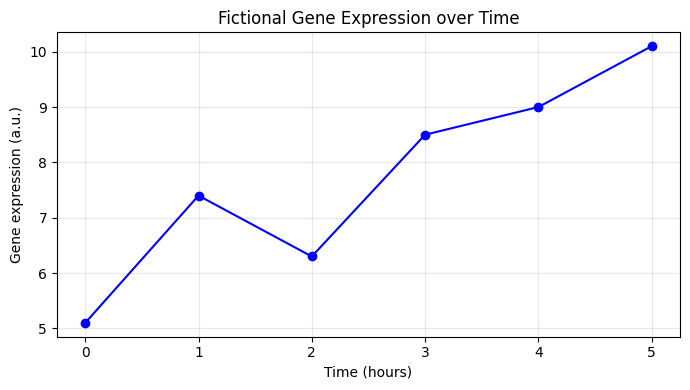

In [25]:
# Create NumPy arrays for time and fictional gene expression measurements.
# Each expression value corresponds to the time point at the same position.
time_points = np.array([0, 1, 2, 3, 4, 5])
expression_over_time = np.array([5.1, 7.4, 6.3, 8.5, 9.0, 10.1])

# Create a new figure with a width of 7 inches and height of 4 inches.
plt.figure(figsize=(7, 4))

# Plot expression values against time.
# Markers show individual measurements; the line connects them.
plt.plot(
    time_points,
    expression_over_time,
    marker="o",
    linestyle="-",
    color="blue"
)

# Label the axes and add a descriptive title.
plt.xlabel("Time (hours)")
plt.ylabel("Gene expression (a.u.)")
plt.title("Fictional Gene Expression over Time")

# Add grid lines with low opacity (alpha=0.3).
plt.grid(True, alpha=0.3)

# Adjust spacing and display the figure.
plt.tight_layout()
plt.show()

# Practice:
# Change marker="o" to marker="s".
# Explain what changes and what stays the same.

## 2. Scatter Plots: Examining Relationships

In medical and biological research, we often want to explore whether two numerical measurements are related.

For example, we might examine the relationship between:

- Gene expression and protein concentration.
- Patient age and blood pressure.
- Blood glucose and insulin levels.

A **scatter plot** displays paired numerical measurements as individual points, helping us identify possible relationships, patterns, and unusual observations.

Unlike a line plot showing change over time, a scatter plot generally does not connect the points because the order of observations may have no meaning.

### Understanding Our Example

We will examine fictional gene-expression and protein-concentration measurements from six samples.

Each sample has two measurements:

- **Horizontal axis (x-axis):** Gene expression in arbitrary units (a.u.).
- **Vertical axis (y-axis):** Protein concentration in arbitrary units (a.u.).
- **Each point:** One sample containing both measurements.

For example, the first sample has a gene-expression value of `5.1` and a protein-concentration value of `1.2`. It will appear at the coordinate `(5.1, 1.2)`.

**Important:** The two arrays must have the same number of elements, and their values must correspond to the same samples in the same order.

If we independently sort the two arrays, we change which measurements are paired and may create a misleading relationship.

### Understanding the Matplotlib Functions

We will use `plt.scatter()` to create the plot.

```python
plt.scatter(x, y)
```

This draws one point for each paired observation.

We can customize the appearance of the points using:

- **`s=70`:** Sets the marker area to 70 points squared.
- **`color="darkorange"`:** Sets the marker color.
- **`edgecolors="black"`:** Adds a black border around each marker.
- **`alpha=0.8`:** Makes the markers slightly transparent.

As in our previous line plot, we will also use `plt.xlabel()`, `plt.ylabel()`, `plt.title()`, and `plt.grid()` to make the figure easier to interpret.

### Interpreting Scatter Plots

A scatter plot can help us visually identify:

- **Positive relationship:** Higher values of one variable tend to occur with higher values of the other.
- **Negative relationship:** Higher values of one variable tend to occur with lower values of the other.
- **No clear relationship:** The points do not show an obvious pattern.

Scatter plots complement the correlation calculations we learned earlier using NumPy.

However, a visible relationship does not establish causation, and a scatter plot alone does not demonstrate statistical significance.

### Let's Create a Scatter Plot with Matplotlib

Now, let's visualize the relationship between fictional gene expression and protein concentration.

In the following example, we will:

- Create two NumPy arrays containing paired measurements from six samples.
- Use `plt.scatter()` to display each sample as a point.
- Customize the marker size, color, border, and transparency.
- Add axis labels, a title, and grid lines.
- Examine the overall pattern between the two measurements.

**Interpretation:** The fictional measurements show a positive relationship: samples with higher gene expression generally have higher protein concentration. This observation does not establish that one measurement causes the other.

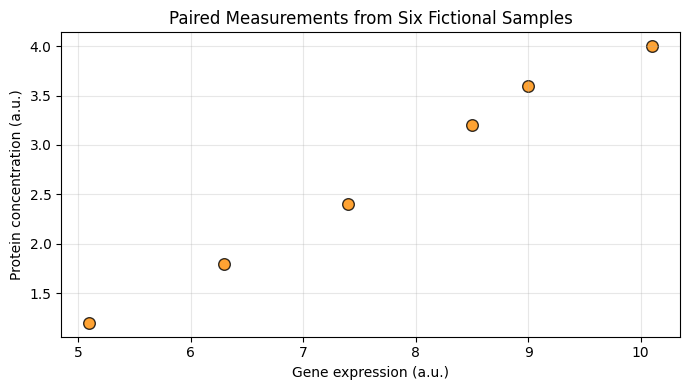

In [26]:
# Create paired measurements from six fictional samples.
# Values at the same index belong to the same sample.
gene_expression = np.array([5.1, 7.4, 6.3, 8.5, 9.0, 10.1])
protein_concentration = np.array([1.2, 2.4, 1.8, 3.2, 3.6, 4.0])

# Create a new figure.
plt.figure(figsize=(7, 4))

# Plot each paired observation as an individual point.
plt.scatter(
    gene_expression,
    protein_concentration,
    s=70,                  # Marker area in points squared
    color="darkorange",    # Marker color
    edgecolors="black",    # Marker border color
    alpha=0.8              # Marker transparency
)

# Add descriptive axis labels and a title.
plt.xlabel("Gene expression (a.u.)")
plt.ylabel("Protein concentration (a.u.)")
plt.title("Paired Measurements from Six Fictional Samples")

# Add grid lines, adjust spacing, and display the plot.
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Practice:
# Identify what one point represents.
# Explain why independently sorting the two arrays would destroy pairing.

## 3. Histograms: Exploring a Distribution

In medical and biological research, we often want to understand how numerical measurements are distributed across a group of observations.

For example, we might examine the distribution of:

- Blood glucose levels across patients.
- Patient ages in a clinical study.
- Gene-expression measurements across biological samples.

A **histogram** helps us visualize the distribution of numerical data by grouping values into intervals called **bins** and counting how many observations fall into each interval.

- **Horizontal axis (x-axis):** Intervals of numerical measurements.
- **Vertical axis (y-axis):** Number of observations in each interval.
- **Each bar:** Represents the number of measurements within a particular interval.

Unlike a bar chart, which compares separate categories, a histogram displays intervals of a numerical variable. The bars typically touch because the intervals are adjacent.

### Understanding Our Example

We will use the fictional `simulated_data` array generated earlier in our NumPy exercises.

This dataset contains:

- **100 rows:** Fictional genes.
- **3 columns:** Fictional experimental conditions.

To examine the distribution of measurements from the first condition, we select:

```python
histogram_values = simulated_data[:, 0]
```

Here, `:` selects all 100 rows, while `0` selects the first column.

This gives us a one-dimensional array containing 100 simulated measurements.

### Understanding Histogram Bins

The number of bins determines how the data range is divided into intervals.

For example:

```python
plt.hist(histogram_values, bins=10)
```

The argument `bins=10` tells Matplotlib to divide the data range into **10 equal-width intervals** and count the observations in each interval.

Changing the number of bins affects how the distribution appears:

- **Fewer bins:** Produce wider intervals and a simpler overall view, but may hide important details.
- **More bins:** Produce narrower intervals and reveal more detail, but may make the distribution appear irregular, especially with small datasets.

The underlying measurements do not change when we change the number of bins.

### Understanding `plt.hist()`

We can create a histogram using:

```python
plt.hist(histogram_values, bins=10)
```

In our example, we will store the three objects returned by `plt.hist()`:

```python
counts, bin_edges, patches = plt.hist(...)
```

- **`counts`:** The number of observations in each bin.
- **`bin_edges`:** The numerical boundaries defining the bins.
- **`patches`:** The graphical objects representing the histogram bars.

For example, when using 10 bins, `counts` contains 10 values and `bin_edges` contains 11 boundaries.

Each bin includes its left boundary and excludes its right boundary, except the final bin, which includes both boundaries.

We can also customize the histogram using:

- **`color="seagreen"`:** Sets the fill color of the bars.
- **`edgecolor="black"`:** Adds black outlines to distinguish adjacent bars.

### Interpreting Histograms

Histograms can help us examine:

- **Center:** Where most measurements are concentrated.
- **Spread:** How widely the values vary.
- **Shape:** Whether the distribution appears approximately symmetric or skewed.
- **Unusual values:** Whether some observations appear far from the majority.

However, the appearance of a histogram depends partly on the chosen bin boundaries and widths. A histogram alone does not establish whether data follow a particular statistical distribution.

### Let's Visualize the Distribution of Simulated Data

Now, let's create a histogram of the first condition in our previously generated dataset.

In the following example, we will:

- Select the first column of `simulated_data`.
- Create a histogram using 10 bins.
- Customize the bar colors and outlines.
- Add descriptive axis labels and a title.
- Display the number of observations in each bin.
- Examine the bin boundaries.
- Verify that the total number of counted observations equals the original dataset size.

**Before running:** Make sure you have executed the earlier simulation cell that creates `simulated_data`.

**Interpretation:** Since our simulated values were generated from a normal distribution, we may expect a roughly bell-shaped pattern. However, with only 100 observations, the histogram will not necessarily appear perfectly symmetric or smooth.

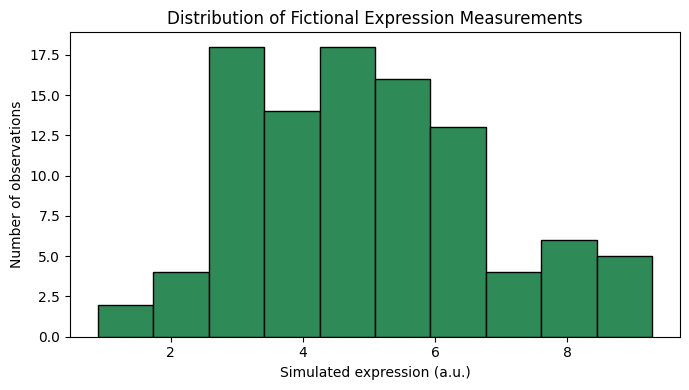

Observations in each bin: [ 2.  4. 18. 14. 18. 16. 13.  4.  6.  5.]
Bin boundaries: [0.8996558  1.73801974 2.57638368 3.41474762 4.25311156 5.0914755
 5.92983944 6.76820338 7.60656732 8.44493126 9.2832952 ]
Total observations counted: 100
Original number of observations: 100


In [27]:
# Select all 100 rows from the first simulated condition (column 0).
histogram_values = simulated_data[:, 0]

# Create a new figure.
plt.figure(figsize=(7, 4))

# Create a histogram with 10 bins.
# Store the bin counts, boundaries, and graphical bar objects.
counts, bin_edges, patches = plt.hist(
    histogram_values,
    bins=10,
    color="seagreen",
    edgecolor="black"
)

# Add axis labels and a descriptive title.
plt.xlabel("Simulated expression (a.u.)")
plt.ylabel("Number of observations")
plt.title("Distribution of Fictional Expression Measurements")

# Adjust spacing and display the histogram.
plt.tight_layout()
plt.show()

# Display the number of observations in each bin.
print("Observations in each bin:", counts)

# Display the boundaries of the histogram bins.
print("Bin boundaries:", bin_edges)

# Add the bin counts to verify that all observations are included.
# int() displays the total as a whole number.
print("Total observations counted:", int(np.sum(counts)))

# .size gives the original number of measurements.
print("Original number of observations:", histogram_values.size)

# Practice:
# Change bins=10 to bins=5, then bins=20.
# Does the underlying dataset change?

## 4. Grouped Bar Plots: Comparing Categories

In medical and biological research, we often want to compare numerical measurements across different groups or experimental conditions.

For example, we might compare:

- Gene expression across treatment conditions.
- Average blood pressure across patient groups.
- Laboratory measurements across different experimental settings.

A **bar plot** displays numerical values for different categories using rectangular bars. The height of each bar represents the corresponding value.

A **grouped bar plot** places related bars next to one another, making it easier to compare multiple measurements within the same category.

### Understanding Our Example

We will compare fictional expression measurements for two genes across three experimental conditions:

- Condition A
- Condition B
- Condition C

For each condition, we have one supplied value for Gene A and one for Gene B.

The horizontal axis will display the experimental conditions, while the vertical axis will display gene expression in arbitrary units (a.u.).

**Important:** These fictional data contain no replicate measurements or estimates of uncertainty. The bars represent the supplied values, not demonstrated treatment effects or statistically significant differences.

### Understanding Figures and Axes

In our previous examples, we used `plt.figure()` to create a figure and `plt.plot()`, `plt.scatter()`, or `plt.hist()` to draw on it.

Matplotlib also provides another approach:

```python
fig, ax = plt.subplots(figsize=(7, 4))
```

This creates two objects:

- **`fig` (Figure):** The entire figure, including the plotting area and surrounding elements.
- **`ax` (Axes):** The plotting area where we display data, labels, and other graphical elements.

We can then use methods associated with `ax` to create and customize the plot.

For example:

```python
ax.bar(...)
ax.set_xlabel(...)
ax.set_title(...)
```

This approach is especially useful when creating more complex figures or multiple plots within one figure.

### Positioning Bars Side by Side

To create a grouped bar plot, we need to position the bars for Gene A and Gene B next to each other.

First, we create numerical positions for the three conditions:

```python
x = np.arange(len(conditions))
```

Here:

- **`len(conditions)`:** Returns the number of conditions, which is `3`.
- **`np.arange(3)`:** Creates the array `[0, 1, 2]`, representing the positions of the three categories.

Next, we define the width of each bar:

```python
width = 0.35
```

To place two bars side by side within each condition, we adjust their horizontal positions:

- **`x - width / 2`:** Moves the centers of Gene A's bars slightly to the left.
- **`x + width / 2`:** Moves the centers of Gene B's bars slightly to the right.

This creates a pair of bars around each condition's central position.

### Understanding the Matplotlib Functions

We will use the following methods:

- **`ax.bar()`:** Creates bars at specified horizontal positions with specified heights.
- **`width=width`:** Sets the width of each bar.
- **`label="Gene A"`:** Assigns a name to the corresponding set of bars.
- **`color="steelblue"`:** Sets the color of the bars.
- **`ax.set_xticks(x)`:** Specifies where tick marks appear along the horizontal axis.
- **`ax.set_xticklabels(conditions)`:** Replaces the numerical positions with condition names.
- **`ax.set_xlabel()` and `ax.set_ylabel()`:** Label the axes.
- **`ax.set_title()`:** Adds a descriptive title.
- **`ax.legend()`:** Displays the labels identifying Gene A and Gene B.
- **`ax.set_axisbelow(True)`:** Places grid lines behind the bars.
- **`ax.grid(axis="y", alpha=0.3)`:** Adds light horizontal grid lines.
- **`fig.tight_layout()`:** Adjusts spacing to prevent labels from being cut off.

### Let's Create a Grouped Bar Plot with Matplotlib

Now, let's compare the expression measurements of two fictional genes across three conditions.

In the following example, we will:

- Define the condition names and corresponding gene-expression values.
- Create numerical positions for the categories using NumPy.
- Define the bar width.
- Draw Gene A and Gene B bars side by side.
- Replace numerical positions with condition names.
- Add axis labels, a title, a legend, and grid lines.
- Display the completed figure.

**Interpretation:** The supplied values for both genes increase from Condition A to Condition C, and Gene A has a higher value than Gene B in each condition. However, these comparisons are descriptive and do not establish statistical significance or treatment effects.

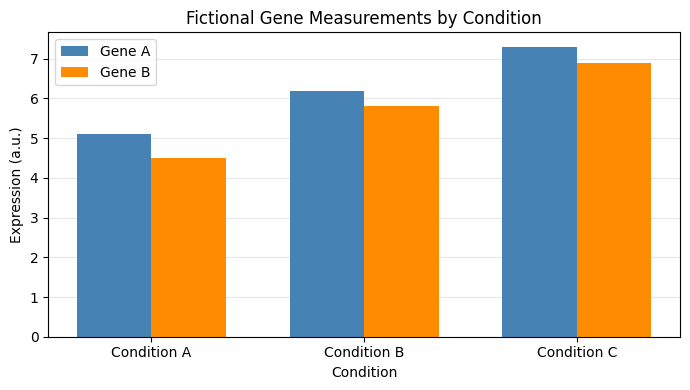

In [28]:
# Define three experimental conditions.
conditions = ["Condition A", "Condition B", "Condition C"]

# Fictional expression measurements for two genes.
gene_a_by_condition = np.array([5.1, 6.2, 7.3])
gene_b_by_condition = np.array([4.5, 5.8, 6.9])

# Create numerical positions for the three conditions: [0, 1, 2].
x = np.arange(len(conditions))

# Set the width of each bar.
width = 0.35

# Create a figure and one plotting area (Axes).
fig, ax = plt.subplots(figsize=(7, 4))

# Plot Gene A bars slightly to the left of each condition's center.
ax.bar(
    x - width / 2,
    gene_a_by_condition,
    width=width,
    label="Gene A",
    color="steelblue"
)

# Plot Gene B bars slightly to the right of each condition's center.
ax.bar(
    x + width / 2,
    gene_b_by_condition,
    width=width,
    label="Gene B",
    color="darkorange"
)

# Place tick marks at the central positions of the groups.
# Replace numerical tick labels with condition names.
ax.set_xticks(x)
ax.set_xticklabels(conditions)

# Add axis labels and a descriptive title.
ax.set_xlabel("Condition")
ax.set_ylabel("Expression (a.u.)")
ax.set_title("Fictional Gene Measurements by Condition")

# Display the legend identifying the two genes.
ax.legend()

# Put horizontal reference lines behind the bars.
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

# Adjust spacing and display the figure.
fig.tight_layout()
plt.show()

## 5. Box Plots: Comparing Distributions

In medical and biological research, we often want to compare how numerical measurements vary across different groups or experimental conditions.

For example, we might compare:

- Blood glucose measurements across patient groups.
- Gene-expression levels across experimental conditions.
- Laboratory measurements across different treatment groups.

A **box plot** (also called a *box-and-whisker plot*) summarizes the distribution of numerical measurements using the median, quartiles, and whiskers.

Unlike a bar plot that displays individual values or summary statistics, a box plot provides information about the **center, spread, and potential outliers** of a distribution.

### Understanding Our Example

We will compare fictional measurements of the same gene across three experimental conditions.

Each condition contains measurements from **five fictional samples**.

Our goal is to visualize how the measurements are distributed within each condition and compare their overall patterns.

### How to Read a Box Plot

A standard box plot contains several important components:

- **Median:** The line inside the box, representing the middle value of the ordered measurements.
- **First quartile (Q1):** The 25th percentile.
- **Third quartile (Q3):** The 75th percentile.
- **Interquartile range (IQR):** The difference between Q3 and Q1, calculated as `Q3 - Q1`.
- **Box:** Extends from Q1 to Q3 and represents the middle 50% of the distribution.
- **Whiskers:** By default, extend to the most extreme observed values within the limits defined by `1.5 × IQR` below Q1 and above Q3.
- **Points beyond the whiskers:** Observations identified as potential outliers according to this plotting rule.

**Important:** Whiskers do not always extend to the minimum and maximum measurements.

Also, potential outliers are not automatically errors. Unusual measurements may reflect biological variation, measurement issues, or other factors that require further investigation.

Percentile calculation conventions can differ, particularly for small datasets. We will use Matplotlib's default calculation.

### Why Display Individual Measurements?

Box plots provide useful summaries, but they do not show every observation.

When a dataset contains only a few samples, important details may be hidden by the summary.

In our example, each condition contains only five measurements. Therefore, we will also display the original values as **black dots** over the box plots.

This allows us to see:

- The actual measurements within each condition.
- How many observations are available.
- Whether measurements are clustered or spread apart.
- How the original values relate to the box plot summaries.

**Important:** Differences between box plots do not automatically indicate statistically significant differences between conditions. Statistical testing and appropriate study design would be needed to evaluate such claims.

### Understanding the Matplotlib Functions

We will use the following functions and operations:

- **`ax.boxplot(boxplot_data)`:** Creates one box plot for each collection of measurements.
- **`ax.set_xticks([1, 2, 3])`:** Specifies the horizontal positions of the three box plots.
- **`ax.set_xticklabels(condition_labels)`:** Displays condition names instead of numerical positions.
- **`ax.scatter()`:** Adds individual measurements as points.
- **`enumerate(boxplot_data, start=1)`:** Provides both the position and the measurements for each condition, starting at position `1`.
- **`[position] * len(values)`:** Creates a list containing the same horizontal position repeated once for each measurement.
- **`s=25`:** Sets the marker area.
- **`zorder=3`:** Draws the points in front of the box plot elements.

For example, if a condition is at position `1` and contains five measurements:

```python
[position] * len(values)
```

produces:

```python
[1, 1, 1, 1, 1]
```

This places all five measurements at the same horizontal position while their vertical positions represent their actual values.

### Let's Create Box Plots with Individual Measurements

Now, let's compare fictional gene-expression distributions across three conditions.

In the following example, we will:

- Define five expression measurements for each condition.
- Organize the measurements into a list of groups.
- Create a box plot for each condition.
- Label the three conditions.
- Overlay the original measurements as black dots.
- Add axis labels, a title, and grid lines.
- Display the completed figure.

**Interpretation:** The box plots help us compare the medians and variability across conditions, while the individual points show the underlying observations. Because each condition has only five fictional measurements, we should avoid drawing strong conclusions about population differences or treatment effects.

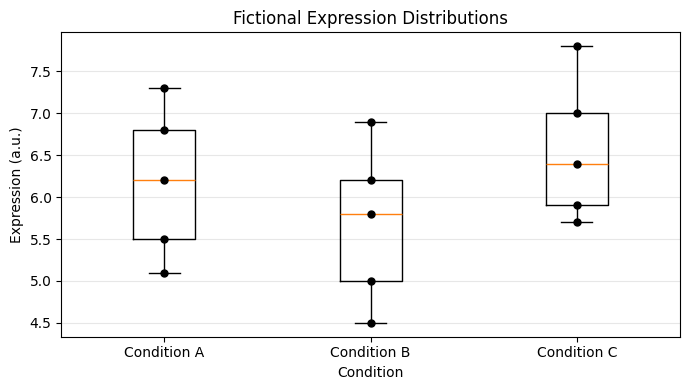

In [29]:
# Define fictional expression measurements from five samples per condition.
expression_levels_A = [5.1, 6.2, 7.3, 5.5, 6.8]
expression_levels_B = [4.5, 5.8, 6.9, 5.0, 6.2]
expression_levels_C = [5.9, 6.4, 7.8, 5.7, 7.0]

# Group the measurements for the three box plots.
boxplot_data = [
    expression_levels_A,
    expression_levels_B,
    expression_levels_C
]

# Define labels for the conditions.
condition_labels = ["Condition A", "Condition B", "Condition C"]

# Create a figure and plotting area.
fig, ax = plt.subplots(figsize=(7, 4))

# Create one box plot per condition at positions 1, 2, and 3.
ax.boxplot(boxplot_data)

# Replace numerical positions with condition names.
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(condition_labels)

# Overlay the original measurements as black dots.
# enumerate() provides the condition position and its values.
for position, values in enumerate(boxplot_data, start=1):
    ax.scatter(
        [position] * len(values),  # Repeat the x-position for each sample
        values,                    # Use the actual measurements as y-values
        color="black",
        s=25,
        zorder=3                   # Draw dots in front of the box plots
    )

# Add axis labels and a descriptive title.
ax.set_xlabel("Condition")
ax.set_ylabel("Expression (a.u.)")
ax.set_title("Fictional Expression Distributions")

# Add light horizontal grid lines.
ax.grid(axis="y", alpha=0.3)

# Adjust spacing and display the figure.
fig.tight_layout()
plt.show()

### Visual Guide: Understanding a Box Plot

Before running the code, explore the illustration here:

**[CDC: Box-and-Whiskers Plot](https://www.cdc.gov/cove/data-visualization-types/box-and-whiskers-plot.html)**

Identify these parts:

- **Q1:** The 25th percentile.
- **Median, or Q2:** The 50th percentile.
- **Q3:** The 75th percentile.
- **Interquartile range, or IQR:** `Q3 − Q1`. The box spans this interval.
- **Whiskers:** In our default Matplotlib plots, these extend to the most extreme observations within `1.5 × IQR` below Q1 and above Q3.
- **Potential outliers:** Observations beyond the whiskers, displayed as separate points.

**Important:** Whiskers do not always reach the minimum and maximum. Points beyond them are not automatically errors and should not be deleted without investigation.

Box plots do not require a bell-shaped distribution.

### Think Before Coding

1. If a very large observation is added, must the median change?
2. What might a wider box suggest about the middle portion of the data?
3. Could two datasets have the same median but different spreads?

**Optional programming reference:** [Matplotlib boxplot documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html)

## 6. Heatmaps: Displaying a Numerical Table

In medical and biological research, we often work with numerical datasets containing many measurements across different samples, genes, or experimental conditions.

For example, we might have:

- Gene-expression measurements across different conditions.
- Laboratory test results across patients.
- Biomarker measurements across tissue samples.

A **heatmap** uses colors to represent numerical values in a two-dimensional table, making it easier to identify patterns and compare measurements.

### Understanding Our Example

We will create a heatmap showing fictional gene-expression measurements for five genes across three experimental conditions.

Our dataset contains:

- **5 rows:** Representing five fictional genes.
- **3 columns:** Representing three experimental conditions.
- **15 cells:** Each containing one numerical measurement.

In the heatmap:

- **Horizontal axis (x-axis):** Experimental conditions.
- **Vertical axis (y-axis):** Genes.
- **Each colored cell:** The expression measurement for one gene under one condition.

Unlike a scatter plot or line plot, a heatmap displays an entire numerical table using colors rather than individual points or connecting lines.

### Understanding the Matplotlib Functions

We will use `ax.imshow()` to display the numerical array as an image.

```python
image = ax.imshow(
    expression_matrix,
    cmap="viridis",
    aspect="auto",
    interpolation="nearest"
)
```

Here:

- **`expression_matrix`:** The two-dimensional NumPy array containing our measurements.
- **`cmap="viridis"`:** Uses a color scale ranging from dark purple for lower values to yellow for higher values.
- **`aspect="auto"`:** Allows the heatmap to fill the plotting area. Cells may be rectangular rather than square.
- **`interpolation="nearest"`:** Displays individual cells without smoothing the values between them.

The variable `image` stores the object returned by `ax.imshow()`. We will use it to create a colorbar.

### Adding Gene and Condition Labels

By default, Matplotlib uses numerical positions for rows and columns.

We can replace those positions with descriptive labels.

For example:

```python
ax.set_xticks(np.arange(len(heatmap_conditions)))
ax.set_xticklabels(heatmap_conditions)
```

These commands place tick marks at the column positions and display the condition names.

Similarly:

```python
ax.set_yticks(np.arange(len(heatmap_gene_names)))
ax.set_yticklabels(heatmap_gene_names)
```

These commands label the rows with gene names.

### Understanding the Colorbar

A **colorbar** explains how the colors in the heatmap correspond to numerical values.

We will add one using:

```python
fig.colorbar(image, ax=ax, label="Expression (a.u.)")
```

Here:

- **`image`:** The heatmap whose color scale we want to display.
- **`ax=ax`:** Associates the colorbar with our plotting area.
- **`label="Expression (a.u.)"`:** Describes the measurements represented by the colors.

**Important:** When comparing different heatmaps, always examine their colorbar scales. The same color may represent different numerical values if the heatmaps use different scales.

### Interpreting Heatmaps

Heatmaps help us identify patterns across rows and columns.

For example, we can examine whether:

- Certain genes have consistently higher or lower expression.
- Some experimental conditions contain generally higher measurements.
- Groups of genes show similar patterns.

In our fictional dataset, Condition C contains the highest expression measurement for each gene.

However, the colors alone do not establish statistical significance, biological mechanisms, or treatment effects.

Also, the order of rows and columns follows the original input data. Our example does not perform clustering or automatically rearrange the genes.

### Let's Create a Gene Expression Heatmap with Matplotlib

Now, let's visualize a two-dimensional NumPy array using a heatmap.

In the following example, we will:

- Create a numerical table containing five genes and three conditions.
- Define descriptive labels for the rows and columns.
- Use `ax.imshow()` to display the measurements as colored cells.
- Customize the color scale and cell appearance.
- Add gene names, condition names, and a descriptive title.
- Include a colorbar to interpret the numerical values.
- Display the completed heatmap.

**Interpretation:** Heatmaps provide a compact visual summary of numerical tables, but the color scale and the underlying measurements must be considered when interpreting patterns.

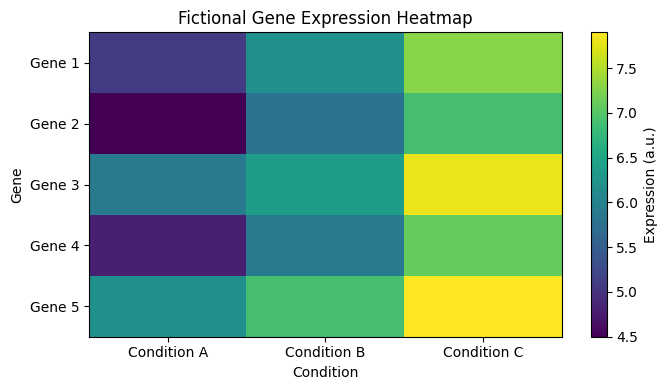

In [30]:
# Create a 5 × 3 array of fictional gene-expression measurements.
# Rows represent genes; columns represent experimental conditions.
expression_matrix = np.array([
    [5.1, 6.2, 7.3],
    [4.5, 5.8, 6.9],
    [5.9, 6.4, 7.8],
    [4.8, 5.9, 7.1],
    [6.2, 6.9, 7.9]
])

# Define labels for the genes and experimental conditions.
heatmap_gene_names = ["Gene 1", "Gene 2", "Gene 3", "Gene 4", "Gene 5"]
heatmap_conditions = ["Condition A", "Condition B", "Condition C"]

# Create a figure and plotting area.
fig, ax = plt.subplots(figsize=(7, 4))

# Display the numerical array as a heatmap.
# Colors represent expression values; nearest avoids smoothing between cells.
image = ax.imshow(
    expression_matrix,
    cmap="viridis",
    aspect="auto",
    interpolation="nearest"
)

# Label the columns with condition names.
ax.set_xticks(np.arange(len(heatmap_conditions)))
ax.set_xticklabels(heatmap_conditions)

# Label the rows with gene names.
ax.set_yticks(np.arange(len(heatmap_gene_names)))
ax.set_yticklabels(heatmap_gene_names)

# Add axis labels and a descriptive title.
ax.set_xlabel("Condition")
ax.set_ylabel("Gene")
ax.set_title("Fictional Gene Expression Heatmap")

# Add a colorbar showing how colors correspond to expression values.
fig.colorbar(image, ax=ax, label="Expression (a.u.)")

# Adjust spacing and display the heatmap.
fig.tight_layout()
plt.show()

## 7. Subplots: Combining Different Views

In medical and biological research, a single dataset can be explored from different perspectives, and each perspective may require a different type of visualization.

For example, we might want to examine:

- How measurements change over time.
- Whether two numerical variables are related.
- How measurements are distributed.
- How distributions differ across experimental conditions.

Instead of creating separate figures for each analysis, we can organize multiple plots within **one figure using subplots**.

### What Are Subplots?

**Subplots** are separate plotting areas arranged within a single figure.

Matplotlib allows us to specify how many rows and columns of plots we want.

For example:

```python
fig, axs = plt.subplots(2, 2)
```

This creates a figure containing **two rows and two columns**, giving us four plotting areas.

Here:

- **`fig`:** Represents the entire figure.
- **`axs`:** A two-dimensional array containing the four plotting areas (Axes objects).

We can access each plotting area using its row and column position.

### Understanding Subplot Positions

Python uses zero-based indexing, so the first row and column have index `0`.

<text weight="medium" size="sm">Subplot layout (2 rows × 2 columns)</text>

<grid columns={2} gap={2}>
  {#each [{p:"axs[0, 0]",t:"Top left",n:"A. Line plot"},{p:"axs[0, 1]",t:"Top right",n:"B. Scatter plot"},{p:"axs[1, 0]",t:"Bottom left",n:"C. Histogram"},{p:"axs[1, 1]",t:"Bottom right",n:"D. Box plot"}] as v}
    <grid-item>
      <box border radius="lg" padding={3} gap={1} align="center">
        <text weight="medium">{v.t}</text>
        <text color="secondary" size="xs">{v.p}</text>
        <text size="sm">{v.n}</text>
      </box>
    </grid-item>
  {/each}
</grid>

For example:

```python
axs[0, 0].plot(...)
```

creates a line plot in the top-left plotting area.

Similarly:

```python
axs[1, 0].hist(...)
```

creates a histogram in the bottom-left plotting area.

Each plotting area can use its own plotting methods, axis labels, and title.

### Adding Titles and Labels

We can customize each subplot independently.

For example:

```python
axs[0, 0].set_title("A. Change over Time")
axs[0, 0].set_xlabel("Time (hours)")
axs[0, 0].set_ylabel("Expression (a.u.)")
```

These commands apply only to the top-left subplot.

We can also add a title for the entire figure:

```python
fig.suptitle("Four Ways to Explore Fictional Numerical Data")
```

The difference is:

- **`set_title()`:** Adds a title to an individual subplot.
- **`fig.suptitle()`:** Adds an overall title to the entire figure.

Finally, `fig.tight_layout()` adjusts spacing to reduce overlap between subplot elements.

### Let's Combine Four Plot Types in One Figure

Now, let's reuse the data and plotting methods from our previous examples to create a figure containing four different visualizations.

We will create:

1. **Top left — Line plot:** Shows how fictional gene expression changes over time.
2. **Top right — Scatter plot:** Shows the relationship between paired gene-expression and protein-concentration measurements.
3. **Bottom left — Histogram:** Shows the distribution of simulated expression measurements.
4. **Bottom right — Box plot:** Compares fictional expression distributions across three conditions.

We will also add individual titles and axis labels to each subplot and a main title for the entire figure.

**Before running:** Make sure you have executed the earlier cells that define `time_points`, `expression_over_time`, `gene_expression`, `protein_concentration`, `histogram_values`, `boxplot_data`, and `condition_labels`.

**Important:** Combining plots into one figure does not mean that all panels represent the same samples or dataset. Each subplot must be interpreted according to its own data, labels, and purpose.

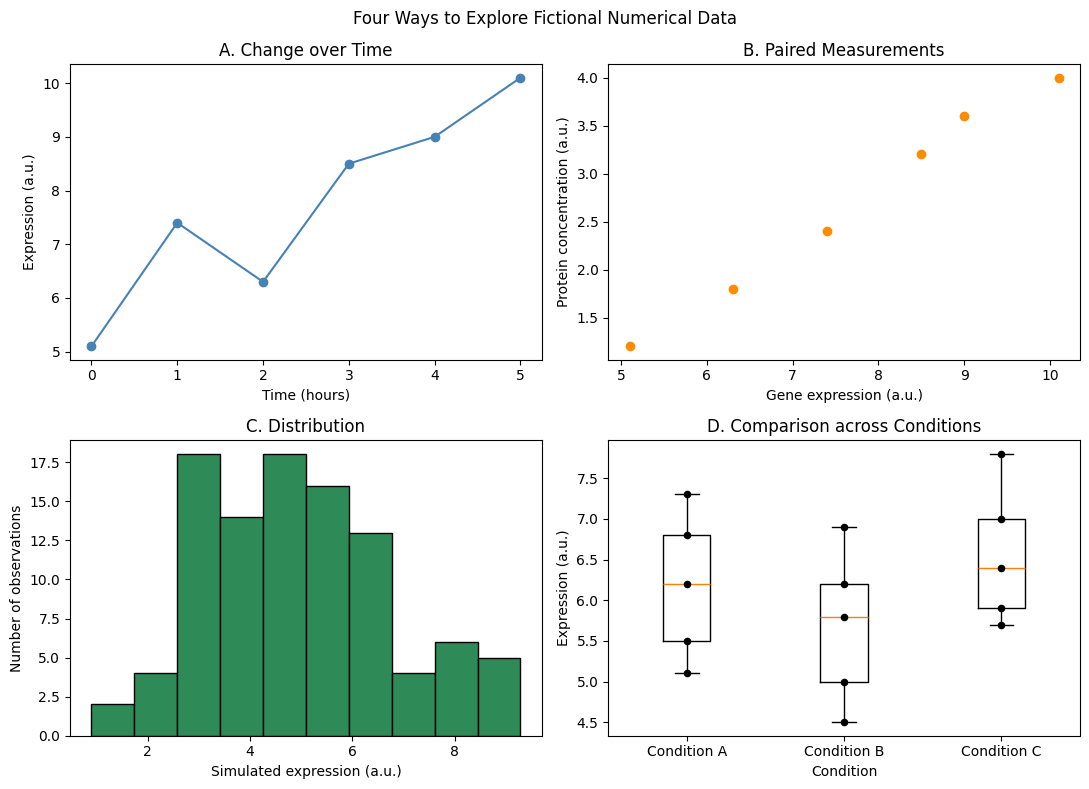

In [31]:
# Create a figure with 2 rows and 2 columns of subplots.
# axs contains the four plotting areas.
fig, axs = plt.subplots(2, 2, figsize=(11, 8))

# Top left: Line plot showing change over time.
axs[0, 0].plot(
    time_points,
    expression_over_time,
    marker="o",
    color="steelblue"
)
axs[0, 0].set_title("A. Change over Time")
axs[0, 0].set_xlabel("Time (hours)")
axs[0, 0].set_ylabel("Expression (a.u.)")

# Top right: Scatter plot showing paired measurements.
axs[0, 1].scatter(
    gene_expression,
    protein_concentration,
    color="darkorange"
)
axs[0, 1].set_title("B. Paired Measurements")
axs[0, 1].set_xlabel("Gene expression (a.u.)")
axs[0, 1].set_ylabel("Protein concentration (a.u.)")

# Bottom left: Histogram showing the distribution of measurements.
axs[1, 0].hist(
    histogram_values,
    bins=10,
    color="seagreen",
    edgecolor="black"
)
axs[1, 0].set_title("C. Distribution")
axs[1, 0].set_xlabel("Simulated expression (a.u.)")
axs[1, 0].set_ylabel("Number of observations")

# Bottom right: Box plots comparing three conditions.
axs[1, 1].boxplot(boxplot_data)

# Label the three conditions.
axs[1, 1].set_xticks([1, 2, 3])
axs[1, 1].set_xticklabels(condition_labels)

# Overlay individual measurements as black dots.
for position, values in enumerate(boxplot_data, start=1):
    axs[1, 1].scatter(
        [position] * len(values),
        values,
        color="black",
        s=20,
        zorder=3
    )

axs[1, 1].set_title("D. Comparison across Conditions")
axs[1, 1].set_xlabel("Condition")
axs[1, 1].set_ylabel("Expression (a.u.)")

# Add a title for the entire figure.
fig.suptitle("Four Ways to Explore Fictional Numerical Data")

# Adjust spacing and display all four plots.
fig.tight_layout()
plt.show()

## 8. Making Comparisons Clear

In medical and biological research, we often display multiple measurements in the same figure to compare their patterns.

For example, we might compare:

- Gene-expression levels of two genes over time.
- Blood glucose measurements from two patient groups.
- Biomarker measurements under different experimental conditions.

When displaying multiple data series, it is important to make the figure **clear, readable, and easy to interpret**.

### How to Make Comparisons Clear

When plotting two or more series, we should:

- **Use meaningful labels:** Clearly identify what each series represents.
- **Choose different markers or line styles:** Help readers distinguish series without relying only on color.
- **Include a legend:** Explain which visual style corresponds to each series.
- **Label the axes and units:** Make the measurements understandable.
- **Use a descriptive title:** Explain what the figure compares.

Using different markers and line styles in addition to colors improves accessibility and helps readers interpret figures printed in grayscale.

### Understanding Our Example

We will compare fictional expression measurements for two genes across six time points.

Both genes are measured at the same time points, allowing us to compare their patterns directly.

We will display:

- **Gene A:** Blue solid line with circular markers.
- **Gene B:** Orange dashed line with square markers.

Each marker represents a measurement at a particular time.

### Understanding the Matplotlib Options

We will use `ax.plot()` twice to display both genes in the same plotting area.

For Gene A:

```python id="u49wrq"
ax.plot(
    comparison_times,
    gene_a_over_time,
    marker="o",
    linestyle="-",
    color="steelblue",
    label="Gene A"
)
```

For Gene B:

```python id="qv24k8"
ax.plot(
    comparison_times,
    gene_b_over_time,
    marker="s",
    linestyle="--",
    color="darkorange",
    label="Gene B"
)
```

The key options are:

- **`marker="o"`:** Displays circular markers.
- **`marker="s"`:** Displays square markers.
- **`linestyle="-"`:** Creates a solid line.
- **`linestyle="--"`:** Creates a dashed line.
- **`color=`:** Specifies the line and marker color.
- **`label=`:** Assigns a descriptive name to each series.

To display the labels in a legend, we use:

```python id="6kavd4"
ax.legend()
```

Matplotlib automatically uses the labels supplied in the plotting commands.

### Let's Compare Two Gene Expression Profiles

Now, let's create a line plot comparing fictional expression measurements for two genes over time.

In the following example, we will:

- Define time points and expression measurements for two genes.
- Plot both genes in the same figure.
- Use different colors, markers, and line styles.
- Add axis labels, a title, and a legend.
- Include grid lines to make the values easier to compare.
- Display the completed figure.

**Interpretation:** Both genes show similar patterns of change over time, with Gene A having higher expression values at every measured time point.

However, similar patterns do not establish that the genes regulate each other or share a biological mechanism. Such conclusions require additional biological evidence and appropriate experimental analysis.

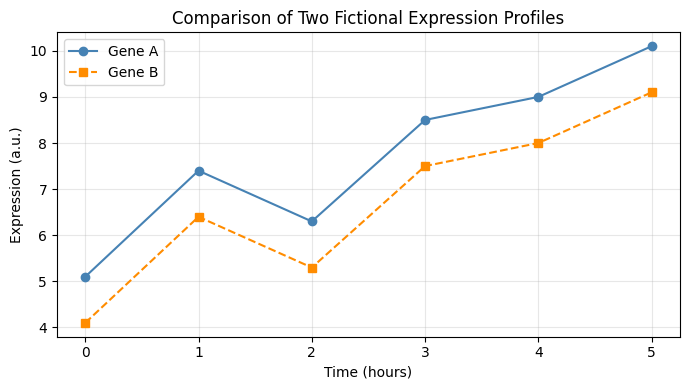

In [32]:
# Define time points for both fictional genes.
comparison_times = np.array([0, 1, 2, 3, 4, 5])

# Expression measurements for Gene A and Gene B.
gene_a_over_time = np.array([5.1, 7.4, 6.3, 8.5, 9.0, 10.1])
gene_b_over_time = np.array([4.1, 6.4, 5.3, 7.5, 8.0, 9.1])

# Create a figure and plotting area.
fig, ax = plt.subplots(figsize=(7, 4))

# Plot Gene A using circles and a solid line.
ax.plot(
    comparison_times,
    gene_a_over_time,
    marker="o",
    linestyle="-",
    color="steelblue",
    label="Gene A"
)

# Plot Gene B using squares and a dashed line.
ax.plot(
    comparison_times,
    gene_b_over_time,
    marker="s",
    linestyle="--",
    color="darkorange",
    label="Gene B"
)

# Add descriptive axis labels and a title.
ax.set_xlabel("Time (hours)")
ax.set_ylabel("Expression (a.u.)")
ax.set_title("Comparison of Two Fictional Expression Profiles")

# Display the legend identifying the two genes.
ax.legend()

# Add light grid lines to help compare measurements.
ax.grid(True, alpha=0.3)

# Adjust spacing and display the figure.
fig.tight_layout()
plt.show()

## 9. Saving a Figure

In medical and biological research, we often need to save figures for use in scientific presentations, reports, manuscripts, or other documents.

Matplotlib allows us to save a figure directly from Python using:

```python
fig.savefig()
```

We can save the same figure in different file formats depending on how we plan to use it.

### Common Figure Formats

Two commonly used formats are:

- **PNG (Portable Network Graphics):** A raster image made of pixels. It is useful for slides, documents, and sharing figures as images.
- **PDF (Portable Document Format):** Can preserve vector elements, such as lines, markers, and text, allowing them to remain sharp when resized.

For scientific figures, PDF is often useful when high-quality scaling is important, while PNG is convenient for presentations and documents.

### Understanding `fig.savefig()`

We can save a figure as a PNG file using:

```python
fig.savefig(
    "expression_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
```

Here:

- **`"expression_comparison.png"`:** Specifies the filename. The `.png` extension tells Matplotlib to save the figure in PNG format.
- **`dpi=300`:** Sets the resolution of the raster image to 300 dots per inch, which is commonly used for high-resolution figures.
- **`bbox_inches="tight"`:** Adjusts the saved figure boundaries to include the content while reducing unnecessary surrounding whitespace.

To save the same figure as a PDF, we can use:

```python
fig.savefig(
    "expression_comparison.pdf",
    bbox_inches="tight"
)
```

The `.pdf` extension tells Matplotlib to save the figure in PDF format.

For vector elements in a PDF, increasing `dpi` is generally unnecessary because those elements can be resized without losing sharpness.

### When Should We Save the Figure?

A useful workflow is:

1. **Create:** Generate the figure and plot the data.
2. **Label:** Add axis labels, titles, and legends.
3. **Save:** Export the completed figure using `fig.savefig()`.
4. **Display:** Show the figure using `plt.show()`.

In our example, we will save the figure before calling `plt.show()`.

### Downloading Figures from Google Colab

When using Google Colab, saved figures are stored in the current runtime's file system.

To download a saved figure:

1. Open the **Files** panel on the left side of Colab.
2. Locate `expression_comparison.png` or `expression_comparison.pdf`.
3. Refresh the Files panel if the files do not appear immediately.
4. Click the three-dot menu next to the file.
5. Select **Download** to save it to your computer.

**Important:** Saving a file in Colab does not automatically download it or permanently store it in Google Drive. Files stored only in the runtime may be lost when the runtime is reset or cleared.

### Let's Save a Matplotlib Figure in PNG and PDF Formats

Now, let's reuse the fictional gene-expression comparison from the previous section and save it in two formats.

In the following example, we will:

- Create a line plot comparing two fictional genes over time.
- Add axis labels, a title, and a legend.
- Save the completed figure as a high-resolution PNG.
- Save the same figure as a PDF.
- Display the figure in Colab.
- Print the saved filenames to confirm which files were created.

Both files will contain the same figure, but their formats provide different options for use in presentations and scientific documents.

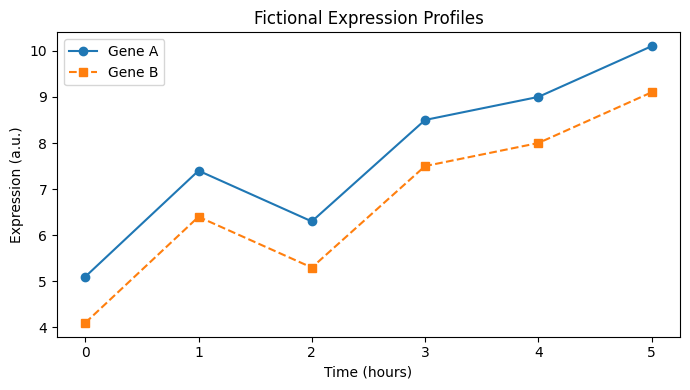

Saved: expression_comparison.png
Saved: expression_comparison.pdf


In [33]:
# Create a figure using the comparison data from the previous cell.
fig, ax = plt.subplots(figsize=(7, 4))

# Plot Gene A using circular markers.
ax.plot(
    comparison_times,
    gene_a_over_time,
    marker="o",
    label="Gene A"
)

# Plot Gene B using square markers and a dashed line.
ax.plot(
    comparison_times,
    gene_b_over_time,
    marker="s",
    linestyle="--",
    label="Gene B"
)

# Add axis labels, a title, and a legend.
ax.set_xlabel("Time (hours)")
ax.set_ylabel("Expression (a.u.)")
ax.set_title("Fictional Expression Profiles")
ax.legend()

# Adjust spacing before saving.
fig.tight_layout()

# Save the figure as a high-resolution PNG image.
# dpi=300 controls raster resolution.
fig.savefig(
    "expression_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

# Save the same figure as a PDF.
# Vector elements remain sharp when resized.
fig.savefig(
    "expression_comparison.pdf",
    bbox_inches="tight"
)

# Display the figure after saving both files.
plt.show()

# Print the filenames of the saved figures.
print("Saved: expression_comparison.png")
print("Saved: expression_comparison.pdf")

# Week 3 Review

You have combined familiar Python skills with new numerical-analysis and visualization tools.

You practiced:

- Creating and indexing NumPy arrays.
- Calculating statistics across rows and columns.
- Selecting data using Boolean masks.
- Standardizing numerical values.
- Generating reproducible simulated data.
- Documenting functions and using optional parameters.
- Choosing plots for different questions.
- Labeling, comparing, arranging, and saving figures.

## Choose the Plot Before Writing the Code

| Question | Useful starting plot |
|---|---|
| How does a measurement change over time? | Line plot |
| How are two paired numerical measurements related? | Scatter plot |
| How are numerical values distributed? | Histogram |
| How do supplied values compare across categories? | Bar plot |
| How do distributions compare across groups? | Box plot with individual observations |
| How do values vary across a numerical table? | Heatmap |

## Independent Practice

Choose one dataset from this lesson.

1. State a question the dataset can help answer.
2. Choose a suitable plot and explain your choice.
3. Create the plot with a descriptive title, axis labels, and units.
4. Change one visual setting and explain whether it improves readability.
5. Save the figure as a PNG.
6. State one conclusion supported by the plot.
7. State one conclusion the plot cannot establish.

**Final reminder:** A convincing-looking graph is not proof of a biological mechanism, clinical benefit, or statistically significant effect. Interpret it in the context of the measurements and study design.

# Week 3 Assignment: Investigating Patient Temperature Patterns


## Scenario: Same Average, Different Clinical Story?

A fictional hospital team recorded temperatures from six adult patients at five scheduled times.

The team wants a clear numerical and visual summary before reviewing the patients’ clinical histories.

Your role is to use **NumPy and Matplotlib** to investigate the records. Can an average temperature hide a changing pattern? Can a single unusual measurement change your interpretation?

These fictional data are for programming practice. Temperature alone cannot establish the presence, cause, or severity of an infection. Do not diagnose patients or recommend treatment.

## Learning Goals

- Create and inspect a two-dimensional NumPy array.
- Select rows and columns using indexing.
- Calculate statistics using the appropriate axis.
- Filter records using Boolean masks.
- Choose and interpret suitable plots.
- Customize and save a figure.
- Explain the limits of a numerical analysis.

## Instructions

- Copy this assignment into a **Text cell** in Google Colab.
- Write all answers in **Code cells** beneath the corresponding sections.
- Write predictions and explanations as Python comments beginning with `#`.
- Use NumPy and Matplotlib for the analysis.
- Display results with clear labels and units.
- Use descriptive variable names.
- Preserve the original dataset.
- Do not use external patient data.

## The Dataset

Each row represents one patient. Each column represents a scheduled measurement time.

All temperatures are in **degrees Celsius (°C)**.

```python
import numpy as np
import matplotlib.pyplot as plt

patient_ids = np.array([
    "P001", "P002", "P003", "P004", "P005", "P006"
])

time_hours = np.array([0, 4, 8, 12, 16])

temperatures = np.array([
    [37.0, 37.1, 37.0, 37.2, 37.1],
    [36.8, 37.2, 37.8, 38.4, 38.8],
    [38.8, 38.4, 37.8, 37.2, 36.8],
    [37.7, 37.8, 37.9, 37.8, 37.8],
    [36.9, 37.0, 40.0, 37.0, 36.9],
    [37.2, 37.3, 37.4, 37.3, 37.2]
])
```

Assume these supplied measurements are numerical and contain no missing entries.

Measurement site, device, medications, symptoms, and clinical history are not supplied. Identifying this missing context is part of the assignment.

---

## Part 1: Understand and Access the Array

### 1. Inspect the dataset.

Display:

- The array’s shape.
- Its number of dimensions.
- Its total number of measurements.

Explain what each dimension represents.

### 2. Select information.

Use NumPy indexing to display:

- Every temperature for P002.
- Every patient’s temperature at hour 8.
- The final recorded temperature for P003.

Label each output.

### 3. Predict before calculating.

Examine P002 and P003.

Before calculating their means, predict:

- Whether their means will be equal.
- Whether their temperature patterns are the same.

Explain your reasoning.

---

## Part 2: Calculate Patient-Level Summaries

### 4. Calculate statistics for each patient.

Use NumPy to calculate:

- Mean temperature.
- Median temperature.
- Standard deviation using `ddof=0`.
- Maximum temperature.
- Temperature range: maximum minus minimum.

Use an axis argument so each result contains one value per patient.

Display a labeled summary for each patient. Round displayed statistics to two decimal places without rounding the underlying arrays.

### 5. Explain the axis.

Why does `axis=1` produce one summary per patient?

What would `np.mean(temperatures, axis=0)` describe instead?

### 6. Investigate P005.

Compare P005’s mean and median.

Explain how the `40.0` measurement affects these summaries differently. Does its unusual appearance prove that it is an error?

---

## Part 3: Filter Records for Review

For this programming exercise, use **38.0°C as an operational review threshold**. This is a supplied selection rule, not a complete diagnostic definition.

### 7. Create a Boolean mask.

Select patients whose maximum recorded temperature is **greater than or equal to 38.0°C**.

Print the Boolean mask and the matching patient identifiers.

Do not remove unselected patients from the original dataset.

### 8. Count threshold-reaching measurements.

Create a Boolean array using:

```python
temperatures >= 38.0
```

Then use:

```python
np.sum(your_boolean_array, axis=1)
```

to count how many recorded measurements reach the threshold for each patient.

In this calculation, `True` contributes `1` and `False` contributes `0`.

Explain why this counts recorded observations rather than the total number of hours spent above the threshold.

### 9. Interpret the filter.

Does selection establish that a patient has an infection?

Does not being selected establish that a patient does not have an infection?

Explain the limitations of the rule.

---

## Part 4: Build a Visual Investigation

### 10. Compare P002 and P003 with a line plot.

Plot both patients on the same axes.

Include:

- Time on the horizontal axis.
- Temperature in °C on the vertical axis.
- A descriptive title.
- Different markers or line styles.
- A legend.

Use your calculated means to explain why an average alone would miss an important difference between these records.

Do not infer a treatment effect: no treatment information is supplied.

### 11. Create a heatmap of all patients.
Display `temperatures` as a heatmap.

Include:

- Patient identifiers as row labels.
- Measurement times as column labels.
- Axis labels.
- A title.
- A colorbar labeled “Temperature (°C).”

Keep the same color scale across the entire matrix.

Explain:

- One pattern that is easier to recognize in the heatmap than in the printed array.
- Why the colors do not identify the cause of a temperature change.

### 12. Compare temperature distributions with box plots.

Create one box plot per patient and overlay the individual measurements.

Include patient identifiers and temperature units.

Explain why a box plot alone cannot show whether readings increased or decreased over time.

### 13. Save a figure.

Save your line plot or heatmap as:

```text
Week_3_Temperature_Figure_YourName.png
```

Use `dpi=300` and `bbox_inches="tight"`.

Save before displaying the figure, download the image, and check that labels are not cut off.

---

## Part 5: Investigate an Unusual Observation

### 14. Perform a sensitivity check.

Create a separate array containing P005’s four measurements other than the hour-8 value:

```python
p005_without_hour8 = np.array([36.9, 37.0, 37.0, 36.9])
```

Compare its mean and standard deviation with those calculated from all five P005 readings.

Explain how much the unusual observation influences the summary.

**Important:** This is a hypothetical sensitivity analysis, not permission to delete the original observation. Keep the original dataset unchanged.

### 15. Propose a verification step.

Identify two questions or checks that could help investigate the hour-8 measurement.

Explain why both of these automatic responses would be inappropriate:

- Deleting it simply because it is unusual.
- Assuming it proves a sudden infection-related deterioration.

---

## Part 6: Write a Clinical Data Handoff

### 16. Summarize your findings.

Write five to seven sentences as Python comments for a fictional supervising clinician.

Include:

- One finding about P002 and P003.
- One finding about P005.
- One explanation of what the threshold filter does and does not show.
- Two additional pieces of clinical or measurement information you would request.
- One limitation of the dataset.

Use numerical results where appropriate. Do not assign diagnoses or recommend treatment.

---

## Final Checks

Before submitting, confirm that:

- Rows represent patients and columns represent times.
- Each patient-level summary contains six values.
- Your filter includes readings exactly equal to the threshold.
- Threshold counts describe observations, not duration.
- Original data remain unchanged.
- Every graph has informative labels and units.
- The line plot preserves time order.
- The heatmap uses one shared color scale.
- The saved figure opens correctly.

## Submission Instructions

1. Run all assignment cells from top to bottom in a fresh session.
2. Keep every answer, explanation, and output visible.
3. Save the completed notebook as a PDF.
4. Open the PDF and check that no questions, code, comments, or outputs are missing or cut off.
5. Name the file:

   `Week_3_Assignment_YourName.pdf`

6. Submit both through **Webcourses**:
   - The completed assignment PDF.
   - Your saved PNG figure.

## Submission Checklist

- [ ] Every question has an answer.
- [ ] Written responses and predictions use `#` comments.
- [ ] NumPy indexing, axis calculations, and Boolean filtering are demonstrated.
- [ ] All three requested plot types are included.
- [ ] Individual measurements appear on the box plots.
- [ ] The sensitivity analysis preserves the original data.
- [ ] Clinical interpretations acknowledge missing context.
- [ ] All code runs without unhandled errors.
- [ ] The PDF and PNG are complete and readable.

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# All records are fictional.
patient_ids = np.array([
    "P001", "P002", "P003", "P004", "P005", "P006"
])

time_hours = np.array([0, 4, 8, 12, 16])

temperatures = np.array([
    [37.0, 37.1, 37.0, 37.2, 37.1],
    [36.8, 37.2, 37.8, 38.4, 38.8],
    [38.8, 38.4, 37.8, 37.2, 36.8],
    [37.7, 37.8, 37.9, 37.8, 37.8],
    [36.9, 37.0, 40.0, 37.0, 36.9],
    [37.2, 37.3, 37.4, 37.3, 37.2]
])

# Preserve an independent copy for the final check.
original_temperatures = temperatures.copy()


# QUESTION 1 — Inspect the dataset.
print("QUESTION 1")
print("Shape:", temperatures.shape)
print("Number of dimensions:", temperatures.ndim)
print("Total measurements:", temperatures.size)

# Shape (6, 5) means six patients and five measurement times.
# Axis 0 corresponds to patients; axis 1 corresponds to times.


# QUESTION 2 — Select information.
print("\nQUESTION 2")
print("P002 temperatures (°C):", temperatures[1, :])
print("All temperatures at hour 8 (°C):", temperatures[:, 2])
print("P003 final temperature (°C):", temperatures[2, -1])


# QUESTION 3 — Prediction before calculating.
#
# I predict that P002 and P003 have equal means because they contain
# the same values in reverse order.
#
# Their patterns differ: P002 increases over time, while P003 decreases.
# Reversing the order does not change the mean.

QUESTION 1
Shape: (6, 5)
Number of dimensions: 2
Total measurements: 30

QUESTION 2
P002 temperatures (°C): [36.8 37.2 37.8 38.4 38.8]
All temperatures at hour 8 (°C): [37.  37.8 37.8 37.9 40.  37.4]
P003 final temperature (°C): 36.8


In [36]:
# QUESTION 4 — Calculate one summary per patient.
mean_temperatures = np.mean(temperatures, axis=1)
median_temperatures = np.median(temperatures, axis=1)
sd_temperatures = np.std(temperatures, axis=1, ddof=0)
maximum_temperatures = np.max(temperatures, axis=1)
minimum_temperatures = np.min(temperatures, axis=1)

temperature_ranges = maximum_temperatures - minimum_temperatures

print("QUESTION 4 — PATIENT SUMMARIES")

for i, patient_id in enumerate(patient_ids):
    print(
        f"{patient_id} | "
        f"Mean: {mean_temperatures[i]:.2f} °C | "
        f"Median: {median_temperatures[i]:.2f} °C | "
        f"SD: {sd_temperatures[i]:.2f} °C | "
        f"Maximum: {maximum_temperatures[i]:.2f} °C | "
        f"Range: {temperature_ranges[i]:.2f} °C"
    )

# Formatting to two decimal places changes only the displayed text.
# The underlying result arrays retain their numerical precision.


# QUESTION 5 — Explain the axis.
#
# axis=1 combines the five columns within each patient row.
# It therefore returns six results: one for each patient.
#
# axis=0 combines patient rows within each time column.
# It returns five results: one mean across patients at each time.

mean_at_each_time = np.mean(temperatures, axis=0)

print("\nQUESTION 5 — MEAN ACROSS PATIENTS AT EACH TIME")
for time, mean_value in zip(time_hours, mean_at_each_time):
    print(f"Hour {time}: {mean_value:.2f} °C")

# zip() pairs the first time with the first mean, and so on.


# QUESTION 6 — Investigate P005.
print("\nQUESTION 6 — P005")
print(f"Mean: {mean_temperatures[4]:.2f} °C")
print(f"Median: {median_temperatures[4]:.2f} °C")

# The 40.0 °C observation raises the mean to 37.56 °C.
# The median remains 37.0 °C because it is the middle sorted value.
#
# The unusual observation does not prove a recording error.
# It could be a genuine measurement or reflect a measurement or entry problem.
# Additional information is needed before deciding how to interpret it.

QUESTION 4 — PATIENT SUMMARIES
P001 | Mean: 37.08 °C | Median: 37.10 °C | SD: 0.07 °C | Maximum: 37.20 °C | Range: 0.20 °C
P002 | Mean: 37.80 °C | Median: 37.80 °C | SD: 0.74 °C | Maximum: 38.80 °C | Range: 2.00 °C
P003 | Mean: 37.80 °C | Median: 37.80 °C | SD: 0.74 °C | Maximum: 38.80 °C | Range: 2.00 °C
P004 | Mean: 37.80 °C | Median: 37.80 °C | SD: 0.06 °C | Maximum: 37.90 °C | Range: 0.20 °C
P005 | Mean: 37.56 °C | Median: 37.00 °C | SD: 1.22 °C | Maximum: 40.00 °C | Range: 3.10 °C
P006 | Mean: 37.28 °C | Median: 37.30 °C | SD: 0.07 °C | Maximum: 37.40 °C | Range: 0.20 °C

QUESTION 5 — MEAN ACROSS PATIENTS AT EACH TIME
Hour 0: 37.40 °C
Hour 4: 37.47 °C
Hour 8: 37.98 °C
Hour 12: 37.48 °C
Hour 16: 37.43 °C

QUESTION 6 — P005
Mean: 37.56 °C
Median: 37.00 °C


In [37]:
# The supplied threshold is an operational review rule.
# It is not a diagnostic test.
review_threshold = 38.0


# QUESTION 7 — Select patients whose maximum reaches the threshold.
review_mask = maximum_temperatures >= review_threshold
selected_patient_ids = patient_ids[review_mask]

print("QUESTION 7")
print("Review mask:", review_mask)
print("Selected patient IDs:", selected_patient_ids)


# QUESTION 8 — Count recorded observations reaching the threshold.
threshold_reached = temperatures >= review_threshold

# True contributes 1 and False contributes 0.
threshold_counts = np.sum(threshold_reached, axis=1)

print("\nQUESTION 8")
print("Measurement-level Boolean array:\n", threshold_reached)

for patient_id, count in zip(patient_ids, threshold_counts):
    print(f"{patient_id}: {count} recorded observations at or above 38.0 °C")

# These are counts at five sampled times, not durations.
# We do not know the temperatures between observations.


# QUESTION 9 — Interpret the filter.
#
# Selection establishes only that at least one supplied temperature
# reached the exercise's threshold.
#
# It does not establish infection, its cause, or its severity.
# Not being selected also does not establish absence of infection.
#
# The rule does not account for symptoms, measurement method,
# medications, individual context, or unobserved temperatures.

QUESTION 7
Review mask: [False  True  True False  True False]
Selected patient IDs: ['P002' 'P003' 'P005']

QUESTION 8
Measurement-level Boolean array:
 [[False False False False False]
 [False False False  True  True]
 [ True  True False False False]
 [False False False False False]
 [False False  True False False]
 [False False False False False]]
P001: 0 recorded observations at or above 38.0 °C
P002: 2 recorded observations at or above 38.0 °C
P003: 2 recorded observations at or above 38.0 °C
P004: 0 recorded observations at or above 38.0 °C
P005: 1 recorded observations at or above 38.0 °C
P006: 0 recorded observations at or above 38.0 °C


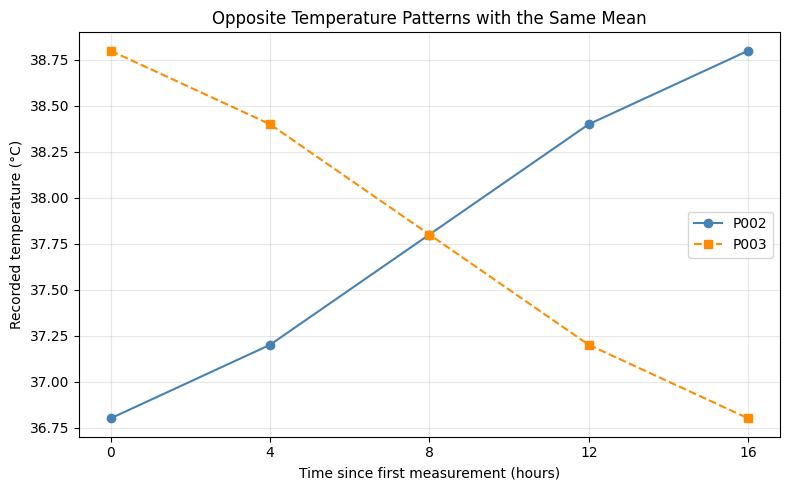

Saved figure: Week_3_Temperature_Figure_YourName.png
P002 mean: 37.80 °C
P003 mean: 37.80 °C


In [38]:
# QUESTION 10 — Compare opposite patterns with the same mean.

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    time_hours,
    temperatures[1, :],
    marker="o",
    linestyle="-",
    color="steelblue",
    label="P002"
)

ax.plot(
    time_hours,
    temperatures[2, :],
    marker="s",
    linestyle="--",
    color="darkorange",
    label="P003"
)

ax.set_xlabel("Time since first measurement (hours)")
ax.set_ylabel("Recorded temperature (°C)")
ax.set_title("Opposite Temperature Patterns with the Same Mean")
ax.set_xticks(time_hours)
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()


# QUESTION 13 — Save before displaying.
figure_filename = "Week_3_Temperature_Figure_YourName.png"

fig.savefig(
    figure_filename,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved figure:", figure_filename)
print(f"P002 mean: {mean_temperatures[1]:.2f} °C")
print(f"P003 mean: {mean_temperatures[2]:.2f} °C")

# Both means are 37.80 °C.
# The mean hides the increasing pattern in P002 and decreasing pattern in P003.
#
# These patterns do not establish a treatment effect:
# treatment and other clinical information were not supplied.
#
# To finish Question 13, download the PNG from Colab's Files panel,
# open it, and check that labels and titles are fully visible.

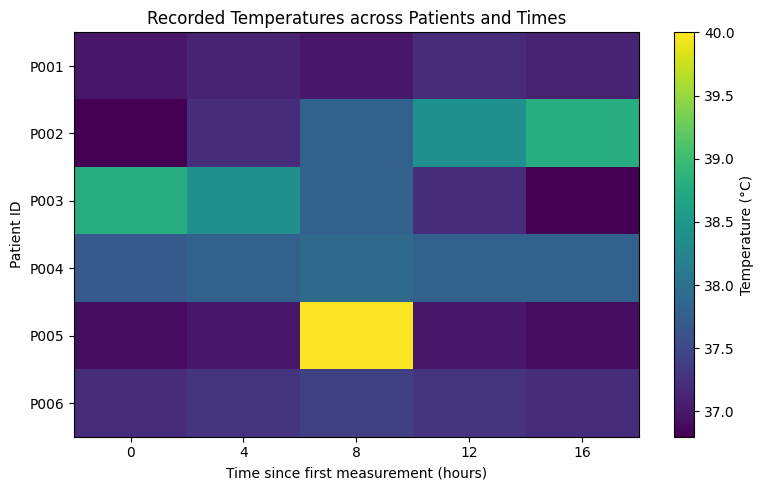

In [39]:
fig, ax = plt.subplots(figsize=(8, 5))

# One image uses one shared color scale across all patients and times.
image = ax.imshow(
    temperatures,
    cmap="viridis",
    aspect="auto",
    interpolation="nearest",
    vmin=np.min(temperatures),
    vmax=np.max(temperatures)
)

ax.set_xticks(np.arange(len(time_hours)))
ax.set_xticklabels(time_hours)

ax.set_yticks(np.arange(len(patient_ids)))
ax.set_yticklabels(patient_ids)

ax.set_xlabel("Time since first measurement (hours)")
ax.set_ylabel("Patient ID")
ax.set_title("Recorded Temperatures across Patients and Times")

fig.colorbar(image, ax=ax, label="Temperature (°C)")

fig.tight_layout()
plt.show()

# The isolated 40.0 °C observation for P005 at hour 8 is easy to locate.
# Opposing patterns in P002 and P003 are also visible across their rows.
#
# Colors encode the supplied temperature values, not their causes.
# They cannot distinguish infection from other explanations.

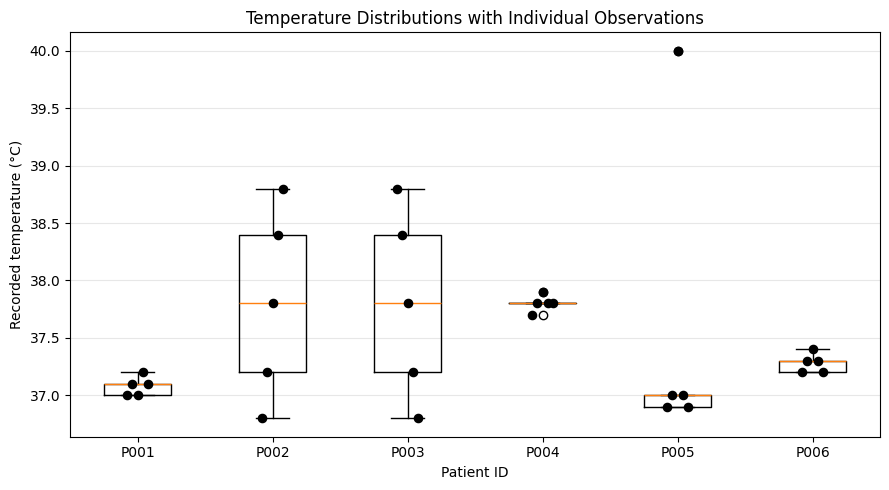

In [40]:
# Each row supplies one patient's five observations.
patient_temperature_lists = []

for row in temperatures:
    patient_temperature_lists.append(row)

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(patient_temperature_lists)

positions = np.arange(1, len(patient_ids) + 1)

ax.set_xticks(positions)
ax.set_xticklabels(patient_ids)

# Display each original observation.
# Small horizontal offsets make repeated values easier to see.
# These offsets are visual only; they do not represent time.
point_offsets = np.linspace(-0.08, 0.08, temperatures.shape[1])

for position, values in enumerate(patient_temperature_lists, start=1):
    ax.scatter(
        position + point_offsets,
        values,
        color="black",
        s=35,
        zorder=3
    )

ax.set_xlabel("Patient ID")
ax.set_ylabel("Recorded temperature (°C)")
ax.set_title("Temperature Distributions with Individual Observations")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

# A box plot summarizes a distribution without preserving time order.
# P002 and P003 have the same values in reverse order, so their boxes match.
#
# The box plot therefore cannot distinguish an increasing trajectory
# from a decreasing trajectory.
#
# The observations within a patient's box are repeated measurements
# from that patient, not five independent patients.
#
# P005's 40.0 °C value is displayed beyond the default whisker.
# An outlier marker does not establish a measurement error.

In [41]:
# QUESTION 14 — Compare summaries with and without the hour-8 value.
# This creates a separate array; the original data remain unchanged.

p005_all_readings = temperatures[4, :].copy()
p005_without_hour8 = np.array([36.9, 37.0, 37.0, 36.9])

mean_with = np.mean(p005_all_readings)
mean_without = np.mean(p005_without_hour8)

sd_with = np.std(p005_all_readings, ddof=0)
sd_without = np.std(p005_without_hour8, ddof=0)

print("QUESTION 14")
print(
    f"All five observations: "
    f"mean = {mean_with:.2f} °C, SD = {sd_with:.2f} °C"
)
print(
    f"Without hour 8: "
    f"mean = {mean_without:.2f} °C, SD = {sd_without:.2f} °C"
)
print(f"Difference in means: {mean_with - mean_without:.2f} °C")
print(f"Difference in SDs: {sd_with - sd_without:.2f} °C")

# Including the observation increases the mean from 36.95 to 37.56 °C,
# a difference of 0.61 °C.
#
# The SD increases from approximately 0.05 to 1.22 °C.
# The observation therefore strongly influences the spread.
#
# This comparison demonstrates sensitivity to one observation.
# It does not establish that removing that observation is justified.


# QUESTION 15 — Propose verification steps.
#
# Check 1:
# Compare the entered value, patient ID, units, and timestamp
# with the original measurement record.
#
# Check 2:
# Review how the measurement was obtained, including device,
# measurement site, technique, and any nearby or repeat measurements.
#
# Automatic deletion would risk discarding a genuine observation.
# Assuming infection-related deterioration would assign a cause
# that the supplied data do not establish.

QUESTION 14
All five observations: mean = 37.56 °C, SD = 1.22 °C
Without hour 8: mean = 36.95 °C, SD = 0.05 °C
Difference in means: 0.61 °C
Difference in SDs: 1.17 °C


In [42]:
# QUESTION 16 — Example seven-sentence handoff.
#
# P002 and P003 both have mean recorded temperatures of 37.80 °C,
# but P002 rises from 36.8 to 38.8 °C while P003 follows the reverse pattern.
#
# Their identical averages therefore hide different time courses.
#
# P005 has an isolated 40.0 °C observation at hour 8, with a mean
# of 37.56 °C and median of 37.00 °C across the five readings.
#
# The supplied review threshold selects P002, P003, and P005,
# but it does not establish infection or exclude it in other patients.
#
# I would request the measurement site, device, and technique,
# particularly for the unusual P005 observation.
#
# I would also request symptoms, medication administration times,
# and relevant clinical history to interpret the trajectories.
#
# Five scheduled observations per patient cannot establish the
# temperatures between measurements or explain their causes.

In [43]:
print("FINAL CHECKS")

print(
    "One summary per patient:",
    mean_temperatures.shape == (len(patient_ids),)
)

print(
    "All statistics have six patient-level results:",
    all(
        result.shape == (6,)
        for result in [
            mean_temperatures,
            median_temperatures,
            sd_temperatures,
            maximum_temperatures,
            temperature_ranges
        ]
    )
)

print(
    "Original temperatures unchanged:",
    np.array_equal(temperatures, original_temperatures)
)

print(
    "Selected patients match expected IDs:",
    np.array_equal(
        selected_patient_ids,
        np.array(["P002", "P003", "P005"])
    )
)

print(
    "Threshold counts match expected values:",
    np.array_equal(
        threshold_counts,
        np.array([0, 2, 2, 0, 1, 0])
    )
)

# The dataset does not contain exactly 38.0 °C.
# Test the boundary separately to confirm that equality is included.
boundary_test = np.array([37.9, 38.0, 38.1])
boundary_mask = boundary_test >= review_threshold

print("Boundary-test values:", boundary_test)
print("Boundary-test selection:", boundary_mask)

print(
    "Exactly 38.0 °C is included:",
    bool(boundary_mask[1])
)

# Final manual checks:
# - Download and open the PNG.
# - Check all plot labels and units.
# - Export and inspect the complete assignment PDF.

FINAL CHECKS
One summary per patient: True
All statistics have six patient-level results: True
Original temperatures unchanged: True
Selected patients match expected IDs: True
Threshold counts match expected values: True
Boundary-test values: [37.9 38.  38.1]
Boundary-test selection: [False  True  True]
Exactly 38.0 °C is included: True
